In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
psychologists = pd.read_csv(
   '/Users/cristinaabrahamse/Documents/Eduvos University/Data Science Honours /Early Prediction of Burnout (Honours Proj.)/Other Datasets/Burnout, emotional symptoms, and work engagement a/Database Psychologists.csv'
)

workers = pd.read_csv(
  '/Users/cristinaabrahamse/Documents/Eduvos University/Data Science Honours /Early Prediction of Burnout (Honours Proj.)/Other Datasets/Burnout, emotional symptoms, and work engagement a/Database workers - PPFI Brazil.csv'
)

## Initial Dataset Inspection

The Burnout, Emotional Symptoms and Work Engagement dataset contains two related samples: psychologists and workers. Both datasets are inspected separately to determine their structure, dimensions, variable availability, missing values and suitability for burnout-risk modelling.

The datasets will remain independent during analysis in accordance with the heterogeneous multi-dataset research design.

In [4]:
# Inspect the dimensions of both datasets
print("Psychologists dataset:")
print(f"Rows: {psychologists.shape[0]}")
print(f"Columns: {psychologists.shape[1]}")

print("\nWorkers dataset:")
print(f"Rows: {workers.shape[0]}")
print(f"Columns: {workers.shape[1]}")

Psychologists dataset:
Rows: 311
Columns: 113

Workers dataset:
Rows: 306
Columns: 88


## Variable Structure Inspection

The variables contained within each dataset are inspected to understand the available demographic, occupational, burnout, emotional wellbeing, work engagement and workplace-related measures. This step supports the identification of the burnout outcome variables and potential predictors for subsequent harmonisation and modelling.

In [5]:
# Column names for both datasets

print("PSYCHOLOGISTS DATASET COLUMNS")
print("=" * 40)

for i, col in enumerate(psychologists.columns, start=1):
    print(f"{i}. {col}")

print("\n" + "=" * 60 + "\n")

print("WORKERS DATASET COLUMNS")
print("=" * 40)

for i, col in enumerate(workers.columns, start=1):
    print(f"{i}. {col}")

PSYCHOLOGISTS DATASET COLUMNS
1. BAT1
2. BAT2
3. BAT3
4. BAT4
5. BAT5
6. BAT6
7. BAT7
8. BAT8
9. BAT9
10. BAT10
11. BAT11
12. BAT12
13. BAT13
14. BAT14
15. BAT15
16. BAT16
17. BAT17
18. BAT18
19. BAT19
20. BAT20
21. BAT21
22. BAT22
23. BAT23
24. Sobre seus pensamentos e sentimentos diante de objetivos (Índice Personalizado de Flexibilidade Psicológica)

25. 1) Esse objetivo é central para a minha vida.
26. 2) Eu acho esse objetivo desafiador. 

27. 3) Eu me sinto estressado(a) ao ir em busca desse objetivo.

28. 4) Sinto emoções desconfortáveis ao buscar esse objetivo (como ansiedade, frustração, culpa, raiva, decepção) 

29. PPFI1
30. PPFI2
31. PPFI3
32. PPFI4
33. PPFI5
34. PPFI6
35. PPFI7
36. PPFI8
37. PPFI9
38. PPFI10
39. PPFI11
40. PPFI12
41. PPFI13
42. PPFI14
43. PPFI15
44. UWES1
45. UWES2
46. UWES3
47. UWES4
48. UWES5
49. UWES6
50. UWES7
51. UWES8
52. UWES9
53. UWES10
54. UWES11
55. UWES12
56. UWES13
57. UWES14
58. UWES15
59. UWES16
60. UWES17
61. DASS1
62. DASS2
63. DASS3
64. DA

## Acronyms Used in This Notebook

| Acronym | Full Name | Meaning in This Study |
|---|---|---|
| **BAT-23** | Burnout Assessment Tool – 23 items | The questionnaire used to measure burnout. It includes Exhaustion, Mental Distance, Cognitive Impairment and Emotional Impairment. |
| **HBS** | Harmonised Burnout Score | The overall burnout score rescaled from its original questionnaire range to a common 0–100 scale for easier comparison across datasets. |
| **LLM** | Large Language Model | Used only to assist with identifying conceptually similar variable families across datasets. All mappings are researcher-validated. |
| **UWES-17** | Utrecht Work Engagement Scale – 17 items | Measures work engagement through Vigour, Dedication and Absorption. |
| **DASS-21** | Depression Anxiety Stress Scales – 21 items | Measures emotional distress through Depression, Anxiety and Stress dimensions. |
| **AAQ-II** | Acceptance and Action Questionnaire – II | Measures psychological inflexibility or experiential avoidance. |
| **PPFI** | Personalized Psychological Flexibility Index | Measures psychological flexibility through Avoidance, Acceptance and Harnessing. |
| **COPSOQ** | Copenhagen Psychosocial Questionnaire | Measures psychosocial workplace factors, such as demands, control and social support. |
| **LR** | Logistic Regression | An interpretable classification model that estimates the probability of Elevated Burnout Risk. |
| **DT** | Decision Tree | An interpretable classification model that creates visible decision rules for classifying burnout risk. |
| **CV** | Cross-Validation | A model-validation method used to assess performance across multiple splits of the training data. |
| **ROC-AUC** | Receiver Operating Characteristic – Area Under the Curve | Measures how well a model distinguishes between Lower Risk and Elevated Risk participants across classification thresholds. |
| **F1-score** | F1-score | A performance measure that balances Precision and Recall. It is useful when the Elevated Risk group is smaller than the Lower Risk group. |
| **TP / TN** | True Positive / True Negative | Correct Elevated Risk and correct Lower Risk classifications. |
| **FP / FN** | False Positive / False Negative | Incorrect classifications. A false negative is an Elevated Risk participant incorrectly classified as Lower Risk. |
| **Cohen’s d** | Cohen’s d effect size | Measures the standardised difference in predictor scores between Lower Risk and Elevated Risk groups. |

## Comparison of Dataset Variables

The variable structures of the psychologist and worker samples are compared to identify variables shared between both datasets and variables unique to each sample. This is important for understanding the degree of heterogeneity between the two datasets before predictor selection and harmonisation.

In [6]:
# Compare variable availability across the datasets

psych_cols = set(psychologists.columns)
worker_cols = set(workers.columns)

common_cols = sorted(psych_cols.intersection(worker_cols))
psych_only = sorted(psych_cols.difference(worker_cols))
worker_only = sorted(worker_cols.difference(psych_cols))

print(f"Common variables: {len(common_cols)}")
print(f"Psychologist-only variables: {len(psych_only)}")
print(f"Worker-only variables: {len(worker_only)}")

print("\nCOMMON VARIABLES:")
print(common_cols)

print("\nPSYCHOLOGIST-ONLY VARIABLES:")
print(psych_only)

print("\nWORKER-ONLY VARIABLES:")
print(worker_only)

Common variables: 74
Psychologist-only variables: 39
Worker-only variables: 14

COMMON VARIABLES:
['AAQ1', 'AAQ2', 'AAQ3', 'AAQ4', 'AAQ5', 'AAQ6', 'AAQ7', 'BAT1', 'BAT10', 'BAT11', 'BAT12', 'BAT13', 'BAT14', 'BAT15', 'BAT16', 'BAT17', 'BAT18', 'BAT19', 'BAT2', 'BAT20', 'BAT21', 'BAT22', 'BAT23', 'BAT3', 'BAT4', 'BAT5', 'BAT6', 'BAT7', 'BAT8', 'BAT9', 'DASS10', 'DASS11', 'DASS12', 'DASS13', 'DASS14', 'DASS15', 'DASS16', 'DASS17', 'DASS18', 'DASS19', 'DASS20', 'DASS21', 'PPFI1', 'PPFI10', 'PPFI11', 'PPFI12', 'PPFI13', 'PPFI14', 'PPFI15', 'PPFI2', 'PPFI3', 'PPFI4', 'PPFI5', 'PPFI6', 'PPFI7', 'PPFI8', 'PPFI9', 'UWES1', 'UWES10', 'UWES11', 'UWES12', 'UWES13', 'UWES14', 'UWES15', 'UWES16', 'UWES17', 'UWES2', 'UWES3', 'UWES4', 'UWES5', 'UWES6', 'UWES7', 'UWES8', 'UWES9']

PSYCHOLOGIST-ONLY VARIABLES:
['1) Esse objetivo é central para a minha vida.', '2) Eu acho esse objetivo desafiador. \n', '3) Eu me sinto estressado(a) ao ir em busca desse objetivo.\n', '4) Sinto emoções desconfortáveis ao 

## Data Quality Assessment

The two samples are assessed for missing values, duplicate observations and data types before any transformations are performed. This ensures that potential data quality issues are identified prior to burnout score construction, predictor selection and model development.

In [7]:
# Assess basic data quality for datasets

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} DATASET")
    print("=" * 50)

    print(f"Shape: {df.shape}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print(f"Total missing values: {df.isna().sum().sum()}")
    print(f"Columns containing missing values: {(df.isna().sum() > 0).sum()}")

    print("\nData types:")
    print(df.dtypes.value_counts())


PSYCHOLOGISTS DATASET
Shape: (311, 113)
Duplicate rows: 0
Total missing values: 43
Columns containing missing values: 2

Data types:
int64      110
float64      2
object       1
Name: count, dtype: int64

WORKERS DATASET
Shape: (306, 88)
Duplicate rows: 0
Total missing values: 0
Columns containing missing values: 0

Data types:
int64     87
object     1
Name: count, dtype: int64


In [8]:
# Display columns containing missing values

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    missing = (
        df.isna()
        .sum()
        .loc[lambda x: x > 0]
        .sort_values(ascending=False)
    )

    print(f"\n{name.upper()} - COLUMNS WITH MISSING VALUES")
    print("=" * 50)

    if len(missing) == 0:
        print("No missing values detected.")
    else:
        print(missing)


PSYCHOLOGISTS - COLUMNS WITH MISSING VALUES
COP20    22
COP21    21
dtype: int64

WORKERS - COLUMNS WITH MISSING VALUES
No missing values detected.


## BAT-23 Burnout Item Validation

Before creating the burnout outcome, the 23 BAT items are validated against the accompanying codebook. The BAT-23 measures four burnout dimensions: Exhaustion, Mental Distance, Cognitive Impairment and Emotional Impairment. Responses are expected to range from 1 (Never) to 5 (Always).

In [9]:
# Define BAT-23 items
bat_items = [f"BAT{i}" for i in range(1, 24)]

# Validate BAT-23 items 
for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - BAT-23 VALIDATION")
    print("=" * 50)

    # Check that all BAT items are present
    missing_columns = [col for col in bat_items if col not in df.columns]

    if missing_columns:
        print("Missing BAT columns:", missing_columns)
    else:
        print("All 23 BAT items are present.")

    # Check missing responses
    print(
        "Missing BAT responses:",
        df[bat_items].isna().sum().sum()
    )

    # Check overall observed range
    print(
        "Observed BAT response range:",
        df[bat_items].min().min(),
        "to",
        df[bat_items].max().max()
    )

    # Show unique values across all BAT items
    unique_values = sorted(
        pd.unique(df[bat_items].values.ravel())
    )

    print("Observed response values:", unique_values)


PSYCHOLOGISTS - BAT-23 VALIDATION
All 23 BAT items are present.
Missing BAT responses: 0
Observed BAT response range: 1 to 5
Observed response values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

WORKERS - BAT-23 VALIDATION
All 23 BAT items are present.
Missing BAT responses: 0
Observed BAT response range: 1 to 5
Observed response values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## BAT-23 Dimension Construction

Following validation of the BAT-23 items, the four burnout dimensions are constructed separately for each sample. The BAT-23 represents burnout through four core dimensions: Exhaustion, Mental Distance, Cognitive Impairment and Emotional Impairment.

Dimension scores are calculated as the mean response across the items belonging to each dimension. Retaining the individual dimension scores provides a transparent representation of the underlying burnout construct before development of the harmonised burnout outcome.

In [10]:
# Define the four BAT-23 burnout dimensions

bat_dimensions = {
    "BAT_Exhaustion": [f"BAT{i}" for i in range(1, 9)],
    "BAT_Mental_Distance": [f"BAT{i}" for i in range(9, 14)],
    "BAT_Cognitive_Impairment": [f"BAT{i}" for i in range(14, 19)],
    "BAT_Emotional_Impairment": [f"BAT{i}" for i in range(19, 24)]
}

# Calculate mean dimension scores separately for both samples
for df in [psychologists, workers]:

    for dimension, items in bat_dimensions.items():
        df[dimension] = df[items].mean(axis=1)

print("BAT-23 dimensions successfully constructed for both datasets.")

BAT-23 dimensions successfully constructed for both datasets.


In [11]:
# Inspect the BAT-23 dimension scores for both datasets

bat_dimension_names = list(bat_dimensions.keys())

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - BAT DIMENSION SUMMARY")
    print("=" * 60)

    print(
        df[bat_dimension_names]
        .describe()
        .round(3)
    )


PSYCHOLOGISTS - BAT DIMENSION SUMMARY
       BAT_Exhaustion  BAT_Mental_Distance  BAT_Cognitive_Impairment  \
count         311.000              311.000                   311.000   
mean            2.705                1.771                     2.223   
std             0.789                0.727                     0.681   
min             1.000                1.000                     1.000   
25%             2.125                1.200                     1.800   
50%             2.750                1.600                     2.200   
75%             3.250                2.200                     2.600   
max             5.000                4.200                     4.600   

       BAT_Emotional_Impairment  
count                   311.000  
mean                      1.730  
std                       0.619  
min                       1.000  
25%                       1.200  
50%                       1.600  
75%                       2.000  
max                       4.200  

WORKE

## Overall BAT-23 Burnout Score Construction

Following construction of the four BAT-23 dimensions, an overall burnout score is calculated for each participant. The overall BAT score represents the mean response across all 23 BAT items and therefore remains on the original 1–5 response scale.

This overall score provides the dataset-specific burnout measure that will subsequently be transformed into the common 0–100 Harmonised Burnout Score (HBS) used across the selected heterogeneous datasets.

In [12]:
# Calculate the overall BAT-23 burnout score

for df in [psychologists, workers]:
    df["BAT_Overall"] = df[bat_items].mean(axis=1)

# Inspect the overall BAT scores
for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - OVERALL BAT SCORE")
    print("=" * 50)

    print(df["BAT_Overall"].describe().round(3))


PSYCHOLOGISTS - OVERALL BAT SCORE
count    311.000
mean       2.185
std        0.578
min        1.000
25%        1.739
50%        2.174
75%        2.587
max        4.000
Name: BAT_Overall, dtype: float64

WORKERS - OVERALL BAT SCORE
count    306.000
mean       2.301
std        0.631
min        1.000
25%        1.837
50%        2.261
75%        2.696
max        4.478
Name: BAT_Overall, dtype: float64


## Harmonised Burnout Score (HBS) Construction

To support comparison of burnout outcomes across heterogeneous datasets, the overall BAT-23 score is transformed to the common Harmonised Burnout Score (HBS), ranging from 0 to 100.

As the BAT-23 uses a theoretical response range from 1 to 5, min-max transformation is applied using the theoretical scale boundaries rather than the observed sample minimum and maximum:

$$
\text{HBS} =
\frac{\text{BAT}_{\text{Overall}} - 1}{5 - 1}
\times 100
$$

Using the theoretical instrument boundaries ensures that the harmonised score is not dependent on the minimum or maximum burnout values observed within a particular sample. Higher HBS values represent greater burnout severity.

In [13]:
# Transform the BAT-23 overall score to the common 0–100 HBS scale

for df in [psychologists, workers]:
    df["HBS"] = ((df["BAT_Overall"] - 1) / 4) * 100

# Validate the resulting HBS
for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - HARMONISED BURNOUT SCORE")
    print("=" * 55)

    print(df["HBS"].describe().round(2))


PSYCHOLOGISTS - HARMONISED BURNOUT SCORE
count    311.00
mean      29.63
std       14.45
min        0.00
25%       18.48
50%       29.35
75%       39.67
max       75.00
Name: HBS, dtype: float64

WORKERS - HARMONISED BURNOUT SCORE
count    306.00
mean      32.52
std       15.76
min        0.00
25%       20.92
50%       31.52
75%       42.39
max       86.96
Name: HBS, dtype: float64


## BAT-23 Elevated Burnout Risk Classification

Unlike datasets for which an established instrument-specific risk threshold is unavailable, the BAT-23 provides published cut-off values for identifying individuals at risk of burnout.

Schaufeli et al. (2023) developed BAT-23 cut-off scores using ROC analysis and proposed a traffic-light classification consisting of a non-burnout group (green), an at-risk group (orange), and a severe burnout group (red). For the total BAT-23 score, a value of 2.59 or greater indicates increased burnout risk, while a score of 3.02 or greater represents the more severe burnout category.

As the present research focuses on the early identification of elevated occupational burnout risk rather than clinical diagnosis, the at-risk threshold of BAT ≥ 2.59 is used to construct the binary target variable.

Using the common 0–100 Harmonised Burnout Score (HBS), the BAT threshold is transformed as follows:

$$
\text{HBS Threshold}
=
\frac{2.59 - 1}{5 - 1}
\times 100
=
39.75
$$

Participants with an HBS below 39.75 are therefore classified as **Lower Risk**, while participants with an HBS of 39.75 or greater are classified as **Elevated Risk**.

The published BAT threshold was derived primarily from European samples and is therefore used here as an evidence-based operational threshold rather than as a clinical diagnostic criterion for the Brazilian samples.

In [14]:
# BAT-23 the published at-risk threshold
BAT_RISK_THRESHOLD = 2.59

# Equivalent threshold on the 0–100 HBS scale
HBS_RISK_THRESHOLD = ((BAT_RISK_THRESHOLD - 1) / 4) * 100

print(f"BAT-23 risk threshold: {BAT_RISK_THRESHOLD}")
print(f"Equivalent HBS threshold: {HBS_RISK_THRESHOLD:.2f}")

# Construct binary burnout-risk target
for df in [psychologists, workers]:

    df["Burnout_Risk"] = (
        df["BAT_Overall"] >= BAT_RISK_THRESHOLD
    ).astype(int)

    df["Burnout_Risk_Label"] = df["Burnout_Risk"].map({
        0: "Lower Risk",
        1: "Elevated Risk"
    })

BAT-23 risk threshold: 2.59
Equivalent HBS threshold: 39.75


In [15]:
# Now we are going to examine the burnout-risk class distributions

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    counts = df["Burnout_Risk_Label"].value_counts()
    percentages = (
        df["Burnout_Risk_Label"]
        .value_counts(normalize=True)
        .mul(100)
    )

    print(f"\n{name.upper()} - BURNOUT RISK DISTRIBUTION")
    print("=" * 55)

    for risk_class in ["Lower Risk", "Elevated Risk"]:
        count = counts.get(risk_class, 0)
        percentage = percentages.get(risk_class, 0)

        print(
            f"{risk_class}: "
            f"{count} participants ({percentage:.1f}%)"
        )


PSYCHOLOGISTS - BURNOUT RISK DISTRIBUTION
Lower Risk: 233 participants (74.9%)
Elevated Risk: 78 participants (25.1%)

WORKERS - BURNOUT RISK DISTRIBUTION
Lower Risk: 211 participants (69.0%)
Elevated Risk: 95 participants (31.0%)


## Predictor Screening and Target Leakage Prevention

Following construction of the burnout-risk outcome, candidate predictor variables are screened before modelling.

Variables directly used to construct the target are excluded from the predictor set to prevent target leakage. This includes the 23 individual BAT items, the derived BAT dimension scores, the overall BAT-23 score, the Harmonised Burnout Score (HBS), and the final burnout-risk variables.

The remaining variables are subsequently examined and mapped to theoretically relevant workplace, psychological, engagement, and demographic constructs before model development.

In [16]:
# Variables derived from or directly contributing to the burnout target

target_related_columns = (
    bat_items
    + list(bat_dimensions.keys())
    + [
        "BAT_Overall",
        "HBS",
        "Burnout_Risk",
        "Burnout_Risk_Label"
    ]
)

print("TARGET-RELATED VARIABLES EXCLUDED FROM MODELLING")
print("=" * 60)

for column in target_related_columns:
    print(column)

print(f"\nTotal excluded target-related variables: {len(target_related_columns)}")

TARGET-RELATED VARIABLES EXCLUDED FROM MODELLING
BAT1
BAT2
BAT3
BAT4
BAT5
BAT6
BAT7
BAT8
BAT9
BAT10
BAT11
BAT12
BAT13
BAT14
BAT15
BAT16
BAT17
BAT18
BAT19
BAT20
BAT21
BAT22
BAT23
BAT_Exhaustion
BAT_Mental_Distance
BAT_Cognitive_Impairment
BAT_Emotional_Impairment
BAT_Overall
HBS
Burnout_Risk
Burnout_Risk_Label

Total excluded target-related variables: 31


## Candidate Predictor Identification

Following removal of all variables directly associated with construction of the burnout-risk outcome, the remaining variables are identified as potential predictors.

Candidate predictors are examined separately for the psychologist and worker samples because the two datasets contain both shared and sample-specific measures. These variables will subsequently undergo conceptual mapping and researcher validation before inclusion in the modelling pipeline.

In [17]:
# Identify remaining candidate predictors after target-related exclusions

psychologist_candidates = [
    col for col in psychologists.columns
    if col not in target_related_columns
]

worker_candidates = [
    col for col in workers.columns
    if col not in target_related_columns
]

# Display psychologist candidate predictors
print("PSYCHOLOGISTS - CANDIDATE PREDICTORS")
print("=" * 60)

for i, col in enumerate(psychologist_candidates, 1):
    print(f"{i}. {col}")

print(f"\nTotal psychologist candidate variables: {len(psychologist_candidates)}")


# Display worker candidate predictors
print("\n\nWORKERS - CANDIDATE PREDICTORS")
print("=" * 60)

for i, col in enumerate(worker_candidates, 1):
    print(f"{i}. {col}")

print(f"\nTotal worker candidate variables: {len(worker_candidates)}")

PSYCHOLOGISTS - CANDIDATE PREDICTORS
1. Sobre seus pensamentos e sentimentos diante de objetivos (Índice Personalizado de Flexibilidade Psicológica)

2. 1) Esse objetivo é central para a minha vida.
3. 2) Eu acho esse objetivo desafiador. 

4. 3) Eu me sinto estressado(a) ao ir em busca desse objetivo.

5. 4) Sinto emoções desconfortáveis ao buscar esse objetivo (como ansiedade, frustração, culpa, raiva, decepção) 

6. PPFI1
7. PPFI2
8. PPFI3
9. PPFI4
10. PPFI5
11. PPFI6
12. PPFI7
13. PPFI8
14. PPFI9
15. PPFI10
16. PPFI11
17. PPFI12
18. PPFI13
19. PPFI14
20. PPFI15
21. UWES1
22. UWES2
23. UWES3
24. UWES4
25. UWES5
26. UWES6
27. UWES7
28. UWES8
29. UWES9
30. UWES10
31. UWES11
32. UWES12
33. UWES13
34. UWES14
35. UWES15
36. UWES16
37. UWES17
38. DASS1
39. DASS2
40. DASS3
41. DASS4
42. DASS5
43. DASS6
44. DASS7
45. DASS8
46. DASS9
47. DASS10
48. DASS11
49. DASS12
50. DASS13
51. DASS14
52. DASS15
53. DASS16
54. DASS17
55. DASS18
56. DASS19
57. DASS20
58. DASS21
59. COP1
60. COP2
61. COP3
6

## Candidate Predictor Structure

The remaining candidate predictors consist of multiple questionnaire instruments and individual assessment items. Before predictor selection, the variable structure is examined to identify groups of variables belonging to common measurement instruments.

Where theoretically and psychometrically appropriate, questionnaire items will subsequently be represented using their established construct or scale scores rather than being treated as unrelated individual predictors. This supports dimensionality reduction, interpretability and consistency with the theoretical constructs represented by the instruments.

In [18]:
# Inspect candidate variable families using common prefixes

import re
from collections import Counter

def get_prefix(column):
    """
    Extract the alphabetical prefix from abbreviated questionnaire
    variables such as PPFI1, AAQ6, DASS01, COP20, etc.
    """
    match = re.match(r"([A-Za-z_]+)", str(column))
    return match.group(1) if match else "Long-text / Other"


for name, candidates in {
    "Psychologists": psychologist_candidates,
    "Workers": worker_candidates
}.items():

    prefix_counts = Counter(get_prefix(col) for col in candidates)

    print(f"\n{name.upper()} - CANDIDATE VARIABLE FAMILIES")
    print("=" * 55)

    for prefix, count in sorted(prefix_counts.items()):
        print(f"{prefix}: {count}")


PSYCHOLOGISTS - CANDIDATE VARIABLE FAMILIES
AAQ: 7
COP: 25
DASS: 21
Long-text / Other: 4
PPFI: 15
Sobre: 1
UWES: 17

WORKERS - CANDIDATE VARIABLE FAMILIES
AAQ: 7
DASS: 21
PPFI: 19
UWES: 17
Valued: 1


## LLM-Assisted Predictor Mapping

Following identification of the candidate variable families, LLM-assisted semantic mapping is used to organise the heterogeneous questionnaire variables into interpretable conceptual predictor domains.

The purpose of the LLM-assisted step is not to automatically determine model inputs or alter the original data. Instead, it assists with identifying conceptually related variables and measurement instruments that may represent common occupational or psychological constructs across heterogeneous datasets.

For the present dataset, the identified instrument families include AAQ, COPSOQ-related variables, DASS-21, PPFI and UWES. Proposed mappings are subsequently subjected to researcher validation using the dataset documentation and established instrument definitions before any predictors are included in model development.

In [19]:
# LLM-assisted conceptual mapping of identified variable families

llm_mapping = pd.DataFrame({
    "Variable_Family": [
        "AAQ",
        "COP",
        "DASS",
        "PPFI",
        "UWES"
    ],

    "Proposed_Construct": [
        "Psychological Flexibility / Inflexibility",
        "Psychosocial Work Environment",
        "Emotional Distress",
        "Psychological Flexibility",
        "Work Engagement"
    ],

    "Potential_Harmonised_Domain": [
        "Psychological Resources",
        "Job Demands and Workplace Resources",
        "Psychological Wellbeing",
        "Psychological Resources",
        "Work Engagement"
    ],

    "Requires_Researcher_Validation": [
        True,
        True,
        True,
        True,
        True
    ]
})

llm_mapping

,Variable_Family,Proposed_Construct,Potential_Harmonised_Domain,Requires_Researcher_Validation
0,AAQ,Psychological Flexibility / Inflexibility,Psychological Resources,True
1,COP,Psychosocial Work Environment,Job Demands and Workplace Resources,True
2,DASS,Emotional Distress,Psychological Wellbeing,True
3,PPFI,Psychological Flexibility,Psychological Resources,True
4,UWES,Work Engagement,Work Engagement,True


## Researcher Validation of LLM-Assisted Predictor Mapping

The conceptual mappings proposed during the LLM-assisted stage are subsequently reviewed before predictor construction. This researcher-validation stage ensures that automated semantic mappings are consistent with the measurement structure and theoretical meaning of the instruments represented in the dataset.

Variables are first examined according to their identified instrument families. Their established constructs and subscales are then considered before deciding whether individual items, subscale scores or overall scale scores should be retained as model predictors.

This validation step prevents automated mappings from directly determining model inputs and maintains researcher oversight of the harmonisation process.

In [20]:
# Inspect variables belonging to each identified instrument family

instrument_prefixes = ["AAQ", "COP", "DASS", "PPFI", "UWES"]

for dataset_name, candidates in {
    "Psychologists": psychologist_candidates,
    "Workers": worker_candidates
}.items():

    print(f"\n{'=' * 70}")
    print(f"{dataset_name.upper()} - INSTRUMENT VARIABLES")
    print("=" * 70)

    for prefix in instrument_prefixes:

        variables = [
            col for col in candidates
            if str(col).upper().startswith(prefix)
        ]

        if variables:
            print(f"\n{prefix} VARIABLES ({len(variables)})")
            print("-" * 45)

            for variable in variables:
                print(variable)


PSYCHOLOGISTS - INSTRUMENT VARIABLES

AAQ VARIABLES (7)
---------------------------------------------
AAQ1
AAQ2
AAQ3
AAQ4
AAQ5
AAQ6
AAQ7

COP VARIABLES (25)
---------------------------------------------
COP1
COP2
COP3
COP4
COP5
COP6
COP7
COP8
COP9
COP10
COP11
COP12
COP13
COP14
COP15
COP16
COP17
COP18
COP19
COP20
COP21
COP22
COP23
COP24
COP25

DASS VARIABLES (21)
---------------------------------------------
DASS1
DASS2
DASS3
DASS4
DASS5
DASS6
DASS7
DASS8
DASS9
DASS10
DASS11
DASS12
DASS13
DASS14
DASS15
DASS16
DASS17
DASS18
DASS19
DASS20
DASS21

PPFI VARIABLES (15)
---------------------------------------------
PPFI1
PPFI2
PPFI3
PPFI4
PPFI5
PPFI6
PPFI7
PPFI8
PPFI9
PPFI10
PPFI11
PPFI12
PPFI13
PPFI14
PPFI15

UWES VARIABLES (17)
---------------------------------------------
UWES1
UWES2
UWES3
UWES4
UWES5
UWES6
UWES7
UWES8
UWES9
UWES10
UWES11
UWES12
UWES13
UWES14
UWES15
UWES16
UWES17

WORKERS - INSTRUMENT VARIABLES

AAQ VARIABLES (7)
---------------------------------------------
AAQ1
AAQ2
AAQ

### Researcher Validation: UWES-17 Work Engagement

The LLM-assisted mapping identified the UWES variable family as representing work engagement. The dataset contains 17 UWES items in both the psychologist and worker samples.

Before constructing an engagement predictor, the item completeness and observed response coding are validated. This ensures that subsequent scoring is based on the measurement structure actually represented in the dataset rather than being determined solely by the LLM-assisted mapping.

In [21]:
# Validate UWES-17 structure 

uwes_items = [f"UWES{i}" for i in range(1, 18)]

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - UWES-17 VALIDATION")
    print("=" * 55)

    missing_columns = [
        col for col in uwes_items
        if col not in df.columns
    ]

    if missing_columns:
        print("Missing UWES columns:", missing_columns)

    else:
        uwes_data = df[uwes_items]

        print("All 17 UWES items are present.")
        print(f"Missing UWES responses: {uwes_data.isna().sum().sum()}")

        observed_values = sorted(
            uwes_data.stack().dropna().unique()
        )

        print(
            f"Observed UWES response range: "
            f"{uwes_data.min().min()} to {uwes_data.max().max()}"
        )

        print(f"Observed UWES response values: {observed_values}")


PSYCHOLOGISTS - UWES-17 VALIDATION
All 17 UWES items are present.
Missing UWES responses: 0
Observed UWES response range: 0 to 6
Observed UWES response values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

WORKERS - UWES-17 VALIDATION
All 17 UWES items are present.
Missing UWES responses: 0
Observed UWES response range: 0 to 6
Observed UWES response values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


### UWES-17 Predictor Construction

Researcher validation supports the LLM-assisted mapping of UWES-17 to the **Work Engagement** domain. All 17 items are present in both samples, contain no missing responses, and use the observed 0–6 response scale.

UWES-17 represents work engagement through three dimensions: Vigour, Dedication and Absorption. Dimension-level and overall engagement scores are therefore constructed using mean item responses. Higher scores represent greater work engagement.

The derived scores are retained as interpretable construct-level variables, while the original UWES items will not be entered individually into the predictive models.

In [22]:
# Define UWES-17 dimensions

uwes_dimensions = {
    "UWES_Vigour": [
        "UWES1", "UWES4", "UWES8",
        "UWES12", "UWES15", "UWES17"
    ],

    "UWES_Dedication": [
        "UWES2", "UWES5", "UWES7",
        "UWES10", "UWES13"
    ],

    "UWES_Absorption": [
        "UWES3", "UWES6", "UWES9",
        "UWES11", "UWES14", "UWES16"
    ]
}

# Construct dimension and overall scores
for df in [psychologists, workers]:

    for dimension, items in uwes_dimensions.items():
        df[dimension] = df[items].mean(axis=1)

    df["UWES_Overall"] = df[uwes_items].mean(axis=1)

print("UWES-17 engagement predictors successfully constructed.")

UWES-17 engagement predictors successfully constructed.


In [23]:
# Inspect constructed UWES-17 scores

uwes_scores = [
    "UWES_Vigour",
    "UWES_Dedication",
    "UWES_Absorption",
    "UWES_Overall"
]

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - UWES-17 SCORE SUMMARY")
    print("=" * 60)

    print(
        df[uwes_scores]
        .describe()
        .round(3)
    )


PSYCHOLOGISTS - UWES-17 SCORE SUMMARY
       UWES_Vigour  UWES_Dedication  UWES_Absorption  UWES_Overall
count      311.000          311.000          311.000       311.000
mean         4.148            4.859            4.132         4.352
std          1.083            1.016            1.055         0.968
min          0.000            0.000            0.000         0.000
25%          3.500            4.400            3.500         3.882
50%          4.333            5.000            4.333         4.529
75%          5.000            5.600            4.833         5.059
max          6.000            6.000            6.000         6.000

WORKERS - UWES-17 SCORE SUMMARY
       UWES_Vigour  UWES_Dedication  UWES_Absorption  UWES_Overall
count      306.000          306.000          306.000       306.000
mean         3.992            4.579            4.045         4.184
std          1.119            1.185            1.118         1.046
min          0.333            0.000            0.500     

### Researcher Validation: DASS-21 Emotional Distress

The LLM-assisted mapping identified the DASS variable family as representing emotional distress and psychological wellbeing. Both samples contain 21 DASS items.

Before constructing any DASS-derived predictors, the completeness and observed response coding of the instrument are validated. This step ensures that subsequent scoring reflects the measurement structure represented in the dataset and supports researcher validation of the proposed LLM mapping.

In [24]:
# Validate DASS-21 structure 

dass_items = [f"DASS{i:02d}" for i in range(1, 22)]

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - DASS-21 VALIDATION")
    print("=" * 55)

    missing_columns = [
        col for col in dass_items
        if col not in df.columns
    ]

    if missing_columns:
        print("Missing DASS columns:", missing_columns)

    else:
        dass_data = df[dass_items]

        print("All 21 DASS items are present.")
        print(f"Missing DASS responses: {dass_data.isna().sum().sum()}")

        observed_values = sorted(
            dass_data.stack().dropna().unique()
        )

        print(
            f"Observed DASS response range: "
            f"{dass_data.min().min()} to {dass_data.max().max()}"
        )

        print(f"Observed DASS response values: {observed_values}")


PSYCHOLOGISTS - DASS-21 VALIDATION
Missing DASS columns: ['DASS01', 'DASS02', 'DASS03', 'DASS04', 'DASS05', 'DASS06', 'DASS07', 'DASS08', 'DASS09']

WORKERS - DASS-21 VALIDATION
All 21 DASS items are present.
Missing DASS responses: 0
Observed DASS response range: 0 to 3
Observed DASS response values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [25]:
# Inspect exact DASS column names in the psychologists dataset

psych_dass_columns = [
    col for col in psychologists.columns
    if str(col).upper().startswith("DASS")
]

print("PSYCHOLOGISTS - EXACT DASS COLUMN NAMES")
print("=" * 55)

for i, col in enumerate(psych_dass_columns, 1):
    print(f"{i}. {repr(col)}")

print(f"\nTotal DASS columns found: {len(psych_dass_columns)}")

PSYCHOLOGISTS - EXACT DASS COLUMN NAMES
1. 'DASS1'
2. 'DASS2'
3. 'DASS3'
4. 'DASS4'
5. 'DASS5'
6. 'DASS6'
7. 'DASS7'
8. 'DASS8'
9. 'DASS9'
10. 'DASS10'
11. 'DASS11'
12. 'DASS12'
13. 'DASS13'
14. 'DASS14'
15. 'DASS15'
16. 'DASS16'
17. 'DASS17'
18. 'DASS18'
19. 'DASS19'
20. 'DASS20'
21. 'DASS21'

Total DASS columns found: 21


In [26]:
# Standardise psychologist DASS column names to match worker convention

dass_rename_map = {
    f"DASS{i}": f"DASS{i:02d}"
    for i in range(1, 10)
}

psychologists.rename(columns=dass_rename_map, inplace=True)

print("Psychologist DASS column names standardised.")
print("\nRenamed columns:")

for old, new in dass_rename_map.items():
    print(f"{old} -> {new}")

Psychologist DASS column names standardised.

Renamed columns:
DASS1 -> DASS01
DASS2 -> DASS02
DASS3 -> DASS03
DASS4 -> DASS04
DASS5 -> DASS05
DASS6 -> DASS06
DASS7 -> DASS07
DASS8 -> DASS08
DASS9 -> DASS09


### DASS-21 Dimension Construction

Following validation and standardisation of the DASS-21 variables, the instrument is represented using its three established dimensions: Depression, Anxiety and Stress.

Dimension-level scores are constructed from the corresponding DASS-21 items. This reduces the individual questionnaire items to interpretable psychological constructs while preserving the conceptual structure of the instrument.

These derived variables remain subject to final researcher validation before inclusion as predictors because emotional distress may be conceptually related to concurrent burnout symptoms.

In [27]:
# Define the DASS-21 dimensions

dass_dimensions = {
    "DASS_Depression": [
        "DASS03", "DASS05", "DASS10",
        "DASS13", "DASS16", "DASS17", "DASS21"
    ],

    "DASS_Anxiety": [
        "DASS02", "DASS04", "DASS07",
        "DASS09", "DASS15", "DASS19", "DASS20"
    ],

    "DASS_Stress": [
        "DASS01", "DASS06", "DASS08",
        "DASS11", "DASS12", "DASS14", "DASS18"
    ]
}

# Construct mean dimension scores
for df in [psychologists, workers]:

    for dimension, items in dass_dimensions.items():
        df[dimension] = df[items].mean(axis=1)

print("DASS-21 dimension scores successfully constructed.")

DASS-21 dimension scores successfully constructed.


In [28]:
# Examine constructed DASS-21 dimension scores

dass_scores = [
    "DASS_Depression",
    "DASS_Anxiety",
    "DASS_Stress"
]

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - DASS-21 DIMENSION SUMMARY")
    print("=" * 60)

    print(
        df[dass_scores]
        .describe()
        .round(3)
    )


PSYCHOLOGISTS - DASS-21 DIMENSION SUMMARY
       DASS_Depression  DASS_Anxiety  DASS_Stress
count          311.000       311.000      311.000
mean             0.723         0.501        0.977
std              0.702         0.572        0.662
min              0.000         0.000        0.000
25%              0.143         0.000        0.429
50%              0.429         0.286        0.857
75%              1.143         0.714        1.429
max              3.000         2.714        2.714

WORKERS - DASS-21 DIMENSION SUMMARY
       DASS_Depression  DASS_Anxiety  DASS_Stress
count          306.000       306.000      306.000
mean             0.799         0.552        1.029
std              0.721         0.593        0.651
min              0.000         0.000        0.000
25%              0.286         0.143        0.429
50%              0.571         0.286        1.000
75%              1.286         0.857        1.429
max              3.000         2.857        2.714


### Researcher Validation: AAQ-7

The LLM-assisted mapping identified the AAQ variable family as representing psychological flexibility/inflexibility. Both samples contain seven AAQ items.

Before constructing an AAQ-derived predictor, the completeness and response coding of the seven items are examined. The resulting scale representation will subsequently be reviewed alongside the PPFI variables because both instrument families relate conceptually to psychological flexibility.

In [29]:
# Validate AAQ-7 structure 

aaq_items = [f"AAQ{i}" for i in range(1, 8)]

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - AAQ-7 VALIDATION")
    print("=" * 55)

    missing_columns = [
        col for col in aaq_items
        if col not in df.columns
    ]

    if missing_columns:
        print("Missing AAQ columns:", missing_columns)

    else:
        aaq_data = df[aaq_items]

        print("All 7 AAQ items are present.")
        print(f"Missing AAQ responses: {aaq_data.isna().sum().sum()}")

        observed_values = sorted(
            aaq_data.stack().dropna().unique()
        )

        print(
            f"Observed AAQ response range: "
            f"{aaq_data.min().min()} to {aaq_data.max().max()}"
        )

        print(f"Observed AAQ response values: {observed_values}")


PSYCHOLOGISTS - AAQ-7 VALIDATION
All 7 AAQ items are present.
Missing AAQ responses: 0
Observed AAQ response range: 1 to 7
Observed AAQ response values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

WORKERS - AAQ-7 VALIDATION
All 7 AAQ items are present.
Missing AAQ responses: 0
Observed AAQ response range: 1 to 7
Observed AAQ response values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


In [30]:
# Inspect AAQ

print("PSYCHOLOGISTS - AAQ SAMPLE")
print("=" * 55)
display(psychologists[aaq_items].head())

print("\nWORKERS - AAQ SAMPLE")
print("=" * 55)
display(workers[aaq_items].head())

print("\nAAQ DESCRIPTIVE STATISTICS")
print("=" * 55)

print("\nPsychologists:")
display(psychologists[aaq_items].describe().round(2))

print("\nWorkers:")
display(workers[aaq_items].describe().round(2))

PSYCHOLOGISTS - AAQ SAMPLE


,AAQ1,AAQ2,AAQ3,AAQ4,AAQ5,AAQ6,AAQ7
0,1,3,5,4,4,5,3
1,2,5,1,1,3,4,6
2,2,1,2,2,2,3,5
3,3,3,4,2,3,3,4
4,3,3,3,2,1,4,3



WORKERS - AAQ SAMPLE


,AAQ1,AAQ2,AAQ3,AAQ4,AAQ5,AAQ6,AAQ7
0,1,3,5,4,4,5,3
1,2,5,1,1,3,4,6
2,2,1,2,2,2,3,5
3,2,4,5,3,5,5,4
4,3,3,4,2,3,3,4



AAQ DESCRIPTIVE STATISTICS

Psychologists:


,AAQ1,AAQ2,AAQ3,AAQ4,AAQ5,AAQ6,AAQ7
count,311.00,311.00,311.00,311.00,311.00,311.00,311.00
mean,2.79,3.06,3.54,2.86,3.09,4.38,3.79
std,1.60,1.78,1.93,1.87,1.67,1.82,2.01
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,2.00,2.00,2.00,1.00,2.00,3.00,2.00
50%,2.00,3.00,3.00,2.00,3.00,5.00,4.00
75%,4.00,4.00,5.00,4.00,4.00,6.00,6.00
max,7.00,7.00,7.00,7.00,7.00,7.00,7.00



Workers:


,AAQ1,AAQ2,AAQ3,AAQ4,AAQ5,AAQ6,AAQ7
count,306.00,306.00,306.00,306.00,306.00,306.00,306.00
mean,2.96,3.28,3.77,3.05,3.39,4.36,3.92
std,1.64,1.80,1.93,1.93,1.82,1.76,2.01
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,2.00,2.00,2.00,1.00,2.00,3.00,2.00
50%,3.00,3.00,4.00,2.00,3.00,4.50,4.00
75%,4.00,5.00,5.00,4.00,5.00,6.00,6.00
max,7.00,7.00,7.00,7.00,7.00,7.00,7.00


### Researcher Validation: PPFI Psychological Flexibility

The LLM-assisted mapping identified the PPFI variable family as representing psychological flexibility. As psychological flexibility is also conceptually related to the construct represented by the AAQ variables, the PPFI structure is examined before either instrument is selected for model inclusion.

The PPFI variables are first inspected for item completeness, naming consistency and response coding across the psychologist and worker samples. This allows the relationship between the AAQ and PPFI measures to be evaluated before constructing the final psychological flexibility predictor representation.

In [31]:
# Inspect PPFI-related variables in both datasets

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    ppfi_columns = [
        col for col in df.columns
        if "PPFI" in str(col).upper()
    ]

    print(f"\n{name.upper()} - PPFI VARIABLES")
    print("=" * 60)

    for i, col in enumerate(ppfi_columns, 1):
        print(f"{i}. {repr(col)}")

    print(f"\nTotal PPFI-related columns: {len(ppfi_columns)}")


PSYCHOLOGISTS - PPFI VARIABLES
1. 'PPFI1'
2. 'PPFI2'
3. 'PPFI3'
4. 'PPFI4'
5. 'PPFI5'
6. 'PPFI6'
7. 'PPFI7'
8. 'PPFI8'
9. 'PPFI9'
10. 'PPFI10'
11. 'PPFI11'
12. 'PPFI12'
13. 'PPFI13'
14. 'PPFI14'
15. 'PPFI15'

Total PPFI-related columns: 15

WORKERS - PPFI VARIABLES
1. 'PPFI01'
2. 'PPFI02'
3. 'PPFI03'
4. 'PPFI04'
5. 'PPFI1'
6. 'PPFI2'
7. 'PPFI3'
8. 'PPFI4'
9. 'PPFI5'
10. 'PPFI6'
11. 'PPFI7'
12. 'PPFI8'
13. 'PPFI9'
14. 'PPFI10'
15. 'PPFI11'
16. 'PPFI12'
17. 'PPFI13'
18. 'PPFI14'
19. 'PPFI15'

Total PPFI-related columns: 19


In [32]:
# Compare PPFI variables between the two datasets

psych_ppfi = [
    col for col in psychologists.columns
    if "PPFI" in str(col).upper()
]

worker_ppfi = [
    col for col in workers.columns
    if "PPFI" in str(col).upper()
]

print("PSYCHOLOGISTS:")
for col in psych_ppfi:
    print(repr(col))

print("\nWORKERS:")
for col in worker_ppfi:
    print(repr(col))

PSYCHOLOGISTS:
'PPFI1'
'PPFI2'
'PPFI3'
'PPFI4'
'PPFI5'
'PPFI6'
'PPFI7'
'PPFI8'
'PPFI9'
'PPFI10'
'PPFI11'
'PPFI12'
'PPFI13'
'PPFI14'
'PPFI15'

WORKERS:
'PPFI01'
'PPFI02'
'PPFI03'
'PPFI04'
'PPFI1'
'PPFI2'
'PPFI3'
'PPFI4'
'PPFI5'
'PPFI6'
'PPFI7'
'PPFI8'
'PPFI9'
'PPFI10'
'PPFI11'
'PPFI12'
'PPFI13'
'PPFI14'
'PPFI15'


In [33]:
# Investigate duplicate-looking PPFI variables in workers dataset

ppfi_pairs = [
    ("PPFI01", "PPFI1"),
    ("PPFI02", "PPFI2"),
    ("PPFI03", "PPFI3"),
    ("PPFI04", "PPFI4")
]

print("WORKERS - PPFI NAMING INVESTIGATION")
print("=" * 60)

for padded, unpadded in ppfi_pairs:

    exact_match = workers[padded].equals(workers[unpadded])

    correlation = workers[[padded, unpadded]].corr().iloc[0, 1]

    print(f"\n{padded} vs {unpadded}")
    print(f"Exact values identical: {exact_match}")
    print(f"Correlation: {correlation:.3f}")

    print("First 10 paired responses:")
    print(
        workers[[padded, unpadded]]
        .head(10)
        .to_string(index=False)
    )

WORKERS - PPFI NAMING INVESTIGATION

PPFI01 vs PPFI1
Exact values identical: False
Correlation: -0.066
First 10 paired responses:
 PPFI01  PPFI1
      6      2
      6      5
      5      7
      5      6
      4      6
      7      1
      6      7
      4      4
      6      2
      6      5

PPFI02 vs PPFI2
Exact values identical: False
Correlation: -0.170
First 10 paired responses:
 PPFI02  PPFI2
      7      2
      7      7
      7      5
      6      5
      4      5
      7      3
      4      6
      7      3
      7      3
      5      5

PPFI03 vs PPFI3
Exact values identical: False
Correlation: -0.258
First 10 paired responses:
 PPFI03  PPFI3
      5      4
      2      7
      6      6
      3      6
      5      7
      7      6
      1      7
      6      5
      2      6
      6      6

PPFI04 vs PPFI4
Exact values identical: False
Correlation: -0.410
First 10 paired responses:
 PPFI04  PPFI4
      7      3
      2      5
      2      6
      2      6
      4      6
   

#### PPFI Variable Resolution

Inspection of the worker dataset identified two similarly named groups of variables: PPFI01–PPFI04 and PPFI1–PPFI15. Direct comparison demonstrated that PPFI01–PPFI04 are not duplicate versions of PPFI1–PPFI4 and therefore must not be renamed or removed as duplicates.

The common PPFI1–PPFI15 block is present in both the psychologist and worker samples and is retained for further validation. The additional PPFI01–PPFI04 variables in the worker dataset are treated separately until their measurement meaning is established.

In [34]:
# Validate common PPFI1–PPFI15 block

ppfi_items = [f"PPFI{i}" for i in range(1, 16)]

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - PPFI-15 VALIDATION")
    print("=" * 55)

    missing_columns = [
        col for col in ppfi_items
        if col not in df.columns
    ]

    if missing_columns:
        print("Missing PPFI columns:", missing_columns)

    else:
        ppfi_data = df[ppfi_items]

        print("All 15 common PPFI items are present.")
        print(f"Missing PPFI responses: {ppfi_data.isna().sum().sum()}")

        observed_values = sorted(
            ppfi_data.stack().dropna().unique()
        )

        print(
            f"Observed PPFI response range: "
            f"{ppfi_data.min().min()} to {ppfi_data.max().max()}"
        )

        print(f"Observed PPFI response values: {observed_values}")


PSYCHOLOGISTS - PPFI-15 VALIDATION
All 15 common PPFI items are present.
Missing PPFI responses: 0
Observed PPFI response range: 1 to 7
Observed PPFI response values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

WORKERS - PPFI-15 VALIDATION
All 15 common PPFI items are present.
Missing PPFI responses: 0
Observed PPFI response range: 1 to 7
Observed PPFI response values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


### Researcher-Validated Psychological Flexibility Measures

Following the LLM-assisted mapping, the AAQ and PPFI variable families were validated against their established measurement structures.

The seven-item AAQ-II represents psychological inflexibility and experiential avoidance. Items are rated on a 1–7 scale and are combined into a single score, with higher scores representing greater psychological inflexibility.

The PPFI contains 15 scored items organised into three dimensions: Avoidance (PPFI1–PPFI5), Acceptance (PPFI6–PPFI10), and Harnessing (PPFI11–PPFI15). These dimensions capture different processes involved in psychological flexibility during personally meaningful goal pursuit.

The AAQ-II and PPFI are therefore not treated as interchangeable measures. The AAQ-II provides a unidimensional representation of psychological inflexibility, whereas the PPFI provides multidimensional representations of avoidance, acceptance and harnessing.

Additional goal-related variables associated with the PPFI questionnaire are not incorporated into the PPFI-15 scale scores.

In [35]:

# AAQ-II: Psychological Inflexibility
aaq_items = [f"AAQ{i}" for i in range(1, 8)]

for df in [psychologists, workers]:

    # Standard AAQ-II summed score: range 7–49
    df["AAQ_Psychological_Inflexibility"] = (
        df[aaq_items].sum(axis=1)
    )


# PPFI-15: Personalized Psychological Flexibility
ppfi_dimensions = {
    "PPFI_Avoidance": [
        "PPFI1", "PPFI2", "PPFI3", "PPFI4", "PPFI5"
    ],

    "PPFI_Acceptance": [
        "PPFI6", "PPFI7", "PPFI8", "PPFI9", "PPFI10"
    ],

    "PPFI_Harnessing": [
        "PPFI11", "PPFI12", "PPFI13", "PPFI14", "PPFI15"
    ]
}

for df in [psychologists, workers]:

    for dimension, items in ppfi_dimensions.items():

        # Mean preserves original interpretable 1–7 response scale
        df[dimension] = df[items].mean(axis=1)


print("AAQ-II and PPFI predictors successfully constructed.")

AAQ-II and PPFI predictors successfully constructed.


In [36]:
psychological_flexibility_scores = [
    "AAQ_Psychological_Inflexibility",
    "PPFI_Avoidance",
    "PPFI_Acceptance",
    "PPFI_Harnessing"
]

for name, df in {
    "Psychologists": psychologists,
    "Workers": workers
}.items():

    print(f"\n{name.upper()} - PSYCHOLOGICAL FLEXIBILITY SUMMARY")
    print("=" * 65)

    print(
        df[psychological_flexibility_scores]
        .describe()
        .round(3)
    )


PSYCHOLOGISTS - PSYCHOLOGICAL FLEXIBILITY SUMMARY
       AAQ_Psychological_Inflexibility  PPFI_Avoidance  PPFI_Acceptance  \
count                          311.000         311.000          311.000   
mean                            23.518           4.570            5.053   
std                              9.816           1.583            1.094   
min                              7.000           1.000            1.000   
25%                             15.500           3.400            4.400   
50%                             22.000           4.600            5.000   
75%                             31.000           5.800            5.800   
max                             49.000           7.000            7.000   

       PPFI_Harnessing  
count          311.000  
mean             3.606  
std              1.137  
min              1.000  
25%              2.800  
50%              3.600  
75%              4.400  
max              7.000  

WORKERS - PSYCHOLOGICAL FLEXIBILITY SUMMARY
   

### Researcher Validation: COP Psychosocial Workplace Variables

The LLM-assisted mapping identified the COP variable family as representing aspects of the psychosocial work environment. Unlike the other major instrument families identified in this dataset, the COP variables are available only for the psychologist sample.

Before constructing workplace-related predictors, the completeness and response structure of the 25 COP variables are examined. The variables are not automatically combined because the instrument may represent multiple distinct psychosocial workplace constructs that should remain separately interpretable.

In [37]:
# Validate COP1–COP25 structure
# Psychologist dataset only

cop_items = [f"COP{i}" for i in range(1, 26)]

print("PSYCHOLOGISTS - COP-25 VALIDATION")
print("=" * 55)

missing_columns = [
    col for col in cop_items
    if col not in psychologists.columns
]

if missing_columns:
    print("Missing COP columns:", missing_columns)

else:
    cop_data = psychologists[cop_items]

    print("All 25 COP items are present.")
    print(f"Missing COP responses: {cop_data.isna().sum().sum()}")

    observed_values = sorted(
        cop_data.stack().dropna().unique()
    )

    print(
        f"Observed COP response range: "
        f"{cop_data.min().min()} to {cop_data.max().max()}"
    )

    print(f"Observed COP response values: {observed_values}")

PSYCHOLOGISTS - COP-25 VALIDATION
All 25 COP items are present.
Missing COP responses: 43
Observed COP response range: 1.0 to 5.0
Observed COP response values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


In [38]:
# Inspect COP variables individually before construct mapping

cop_summary = pd.DataFrame({
    "Variable": cop_items,
    "Non_Missing": psychologists[cop_items].notna().sum().values,
    "Missing": psychologists[cop_items].isna().sum().values,
    "Mean": psychologists[cop_items].mean().values,
    "Std": psychologists[cop_items].std().values,
    "Min": psychologists[cop_items].min().values,
    "Max": psychologists[cop_items].max().values
})

cop_summary = cop_summary.round(3)

display(cop_summary)

,Variable,Non_Missing,Missing,Mean,Std,Min,Max
0,COP1,311,0,2.656,1.136,1.0,5.0
1,COP2,311,0,2.701,1.225,1.0,5.0
2,COP3,311,0,2.759,1.253,1.0,5.0
3,COP4,311,0,2.601,1.433,1.0,5.0
4,COP5,311,0,3.772,1.284,1.0,5.0
5,COP6,311,0,4.550,0.885,1.0,5.0
6,COP7,311,0,4.293,1.029,1.0,5.0
7,COP8,311,0,3.865,1.093,1.0,5.0
8,COP9,311,0,4.003,1.123,1.0,5.0
9,COP10,311,0,4.386,0.967,1.0,5.0


### COPSOQ Workplace Demands and Resources

The COP variables were researcher-validated using the dataset codebook and identified as COPSOQ measures of workplace demands and resources.

The 25 items represent separate psychosocial workplace dimensions rather than a single overall construct. Accordingly, dimension-level predictors are constructed for quantitative demands, cognitive demands, emotional demands, hiding emotions, possibilities for development, social support, social relations and control.

Mean scores are used to retain the original 1–5 response scale and provide interpretable dimension-level representations. Missing responses within the Social Support dimension are handled using available-item means rather than imputing individual questionnaire responses.

In [39]:
# Define COPSOQ workplace dimensions

copsoq_dimensions = {
    "COP_Quantitative_Demands": [
        "COP1", "COP2", "COP3", "COP4"
    ],

    "COP_Cognitive_Demands": [
        "COP5", "COP6", "COP7", "COP8"
    ],

    "COP_Emotional_Demands": [
        "COP9", "COP10", "COP11"
    ],

    "COP_Hiding_Emotions": [
        "COP12", "COP13"
    ],

    "COP_Possibilities_Development": [
        "COP14", "COP15", "COP16", "COP17"
    ],

    "COP_Social_Support": [
        "COP18", "COP19", "COP20", "COP21"
    ],

    "COP_Social_Relations": [
        "COP22", "COP23"
    ],

    "COP_Control": [
        "COP24", "COP25"
    ]
}

# Construct dimension-level mean scores

for dimension, items in copsoq_dimensions.items():
    psychologists[dimension] = psychologists[items].mean(
        axis=1,
        skipna=True
    )

print("COPSOQ workplace dimensions successfully constructed.")

COPSOQ workplace dimensions successfully constructed.


In [40]:
# Inspect constructed COPSOQ dimensions

copsoq_scores = list(copsoq_dimensions.keys())

print("PSYCHOLOGISTS - COPSOQ DIMENSION SUMMARY")
print("=" * 70)

display(
    psychologists[copsoq_scores]
    .describe()
    .round(3)
)

print("\nMissing derived COPSOQ scores:")
print(
    psychologists[copsoq_scores]
    .isna()
    .sum()
)

PSYCHOLOGISTS - COPSOQ DIMENSION SUMMARY


,COP_Quantitative_Demands,COP_Cognitive_Demands,COP_Emotional_Demands,COP_Hiding_Emotions,COP_Possibilities_Development,COP_Social_Support,COP_Social_Relations,COP_Control
count,311.000,311.000,311.000,311.000,311.000,311.000,311.000,311.000
mean,2.679,4.120,4.208,3.182,4.225,3.011,3.315,3.309
std,0.995,0.763,0.909,1.072,0.616,1.088,0.703,1.096
min,1.000,1.250,1.000,1.000,1.500,1.000,1.000,1.000
25%,2.000,3.750,3.667,2.500,4.000,2.250,3.000,2.500
50%,2.500,4.250,4.667,3.000,4.250,3.000,3.000,3.500
75%,3.500,4.750,5.000,4.000,4.500,4.000,4.000,4.000
max,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000



Missing derived COPSOQ scores:
COP_Quantitative_Demands         0
COP_Cognitive_Demands            0
COP_Emotional_Demands            0
COP_Hiding_Emotions              0
COP_Possibilities_Development    0
COP_Social_Support               0
COP_Social_Relations             0
COP_Control                      0
dtype: int64


In [41]:
# Check completeness of the COPSOQ Social Support dimension

social_support_items = ["COP18", "COP19", "COP20", "COP21"]

psychologists["COP_Social_Support_Items_Answered"] = (
    psychologists[social_support_items]
    .notna()
    .sum(axis=1)
)

print("COPSOQ SOCIAL SUPPORT - ITEMS ANSWERED")
print("=" * 55)

print(
    psychologists["COP_Social_Support_Items_Answered"]
    .value_counts()
    .sort_index()
)

print("\nPercentage distribution:")
print(
    psychologists["COP_Social_Support_Items_Answered"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

COPSOQ SOCIAL SUPPORT - ITEMS ANSWERED
COP_Social_Support_Items_Answered
2     20
3      3
4    288
Name: count, dtype: int64

Percentage distribution:
COP_Social_Support_Items_Answered
2     6.43
3     0.96
4    92.60
Name: proportion, dtype: float64


In [42]:
# Recalculate COPSOQ Social Support using 2 out of 4 answered items 

social_support_items = ["COP18", "COP19", "COP20", "COP21"]

social_support_count = (
    psychologists[social_support_items]
    .notna()
    .sum(axis=1)
)

psychologists["COP_Social_Support"] = (
    psychologists[social_support_items]
    .mean(axis=1)
    .where(social_support_count >= 2)
)

print("COPSOQ Social Support scoring validation")
print("=" * 55)
print(
    f"Valid Social Support scores: "
    f"{psychologists['COP_Social_Support'].notna().sum()}"
)
print(
    f"Missing Social Support scores: "
    f"{psychologists['COP_Social_Support'].isna().sum()}"
)

COPSOQ Social Support scoring validation
Valid Social Support scores: 311
Missing Social Support scores: 0


## Researcher Validation and Final Predictor Selection

Following LLM-assisted construct mapping and instrument-level validation, the derived variables were reviewed for final inclusion in the predictive modelling stage.

Predictors were selected based on their conceptual relevance to occupational burnout, availability within each dataset, interpretability, and separation from the BAT-derived burnout outcome. Variables directly used to construct the burnout target were excluded from the predictor set to prevent target leakage.

Because the psychologist and worker samples contain different available constructs, predictor selection is performed independently for each dataset while maintaining the same overall modelling framework.

In [43]:

# RESEARCHER-VALIDATED CANDIDATE PREDICTOR SETS

# Work engagement
uwes_predictors = [
    "UWES_Vigour",
    "UWES_Dedication",
    "UWES_Absorption"
]

# Emotional distress
dass_predictors = [
    "DASS_Depression",
    "DASS_Anxiety",
    "DASS_Stress"
]

# Psychological inflexibility
aaq_predictors = [
    "AAQ_Psychological_Inflexibility"
]

# Psychological flexibility
ppfi_predictors = [
    "PPFI_Avoidance",
    "PPFI_Acceptance",
    "PPFI_Harnessing"
]

# Workplace demands/resources
# Available in psychologist sample only
copsoq_predictors = [
    "COP_Quantitative_Demands",
    "COP_Cognitive_Demands",
    "COP_Emotional_Demands",
    "COP_Hiding_Emotions",
    "COP_Possibilities_Development",
    "COP_Social_Support",
    "COP_Social_Relations",
    "COP_Control"
]

In [44]:
# Researcher validation of harmonised predictor constructs

predictor_validation = pd.DataFrame([
    {
        "Construct": "Work Engagement",
        "Variables": "UWES Vigour, Dedication, Absorption",
        "Harmonised_Domain": "Work Engagement",
        "Decision": "Retain",
        "Rationale": "Represents engagement with work and is conceptually relevant to occupational burnout."
    },
    {
        "Construct": "Psychological Inflexibility",
        "Variables": "AAQ Psychological Inflexibility",
        "Harmonised_Domain": "Psychological Resources",
        "Decision": "Retain",
        "Rationale": "Represents experiential avoidance and psychological inflexibility."
    },
    {
        "Construct": "Personalized Psychological Flexibility",
        "Variables": "PPFI Avoidance, Acceptance, Harnessing",
        "Harmonised_Domain": "Psychological Resources",
        "Decision": "Retain",
        "Rationale": "Provides multidimensional representations of psychological flexibility."
    },
    {
        "Construct": "Emotional Distress",
        "Variables": "DASS Depression, Anxiety, Stress",
        "Harmonised_Domain": "Psychological Wellbeing",
        "Decision": "Retain with caution",
        "Rationale": "Relevant to burnout risk but may represent concurrent psychological symptoms rather than purely antecedent risk factors."
    },
    {
        "Construct": "Psychosocial Work Environment",
        "Variables": "COPSOQ demands and resources",
        "Harmonised_Domain": "Job Demands and Workplace Resources",
        "Decision": "Retain - Psychologists only",
        "Rationale": "Provides interpretable workplace demand and resource indicators relevant to occupational burnout."
    }
])

display(predictor_validation)

,Construct,Variables,Harmonised_Domain,Decision,Rationale
0,Work Engagement,"UWES Vigour, Dedication, Absorption",Work Engagement,Retain,Represents engagement with work and is concept...
1,Psychological Inflexibility,AAQ Psychological Inflexibility,Psychological Resources,Retain,Represents experiential avoidance and psycholo...
2,Personalized Psychological Flexibility,"PPFI Avoidance, Acceptance, Harnessing",Psychological Resources,Retain,Provides multidimensional representations of p...
3,Emotional Distress,"DASS Depression, Anxiety, Stress",Psychological Wellbeing,Retain with caution,Relevant to burnout risk but may represent con...
4,Psychosocial Work Environment,COPSOQ demands and resources,Job Demands and Workplace Resources,Retain - Psychologists only,Provides interpretable workplace demand and re...


In [45]:

# DATASET-SPECIFIC CANDIDATE MODEL PREDICTORS

psychologist_candidate_predictors = (
    copsoq_predictors
    + uwes_predictors
    + aaq_predictors
    + ppfi_predictors
    + dass_predictors
)

worker_candidate_predictors = (
    uwes_predictors
    + aaq_predictors
    + ppfi_predictors
    + dass_predictors
)

print("PSYCHOLOGISTS")
print("=" * 55)
print(f"Candidate predictors: {len(psychologist_candidate_predictors)}")

for i, predictor in enumerate(psychologist_candidate_predictors, 1):
    print(f"{i}. {predictor}")

print("\nWORKERS")
print("=" * 55)
print(f"Candidate predictors: {len(worker_candidate_predictors)}")

for i, predictor in enumerate(worker_candidate_predictors, 1):
    print(f"{i}. {predictor}")

PSYCHOLOGISTS
Candidate predictors: 18
1. COP_Quantitative_Demands
2. COP_Cognitive_Demands
3. COP_Emotional_Demands
4. COP_Hiding_Emotions
5. COP_Possibilities_Development
6. COP_Social_Support
7. COP_Social_Relations
8. COP_Control
9. UWES_Vigour
10. UWES_Dedication
11. UWES_Absorption
12. AAQ_Psychological_Inflexibility
13. PPFI_Avoidance
14. PPFI_Acceptance
15. PPFI_Harnessing
16. DASS_Depression
17. DASS_Anxiety
18. DASS_Stress

WORKERS
Candidate predictors: 10
1. UWES_Vigour
2. UWES_Dedication
3. UWES_Absorption
4. AAQ_Psychological_Inflexibility
5. PPFI_Avoidance
6. PPFI_Acceptance
7. PPFI_Harnessing
8. DASS_Depression
9. DASS_Anxiety
10. DASS_Stress


### Predictor Redundancy Assessment

Before finalising the modelling variables, relationships between the researcher-validated candidate predictors were examined to identify potential redundancy and strong inter-predictor associations.

This assessment is particularly relevant for Logistic Regression because strongly correlated predictors may reduce coefficient stability and complicate interpretation. Correlation is therefore used as a diagnostic tool rather than as an automatic feature-removal rule. Final predictor inclusion remains based on both statistical evidence and theoretical relevance.

In [46]:

# PREDICTOR REDUNDANCY / CORRELATION ASSESSMENT

def assess_predictor_correlations(df, predictors, dataset_name, threshold=0.70):

    # Correlation matrix
    corr_matrix = df[predictors].corr()

    print(f"\n{dataset_name.upper()} - STRONG PREDICTOR CORRELATIONS")
    print("=" * 65)
    print(f"Threshold: |r| >= {threshold}")

    strong_pairs = []

    for i in range(len(predictors)):
        for j in range(i + 1, len(predictors)):

            r = corr_matrix.loc[predictors[i], predictors[j]]

            if abs(r) >= threshold:
                strong_pairs.append(
                    (predictors[i], predictors[j], r)
                )

    if strong_pairs:

        strong_corr_df = pd.DataFrame(
            strong_pairs,
            columns=[
                "Predictor_1",
                "Predictor_2",
                "Correlation"
            ]
        )

        strong_corr_df["Absolute_Correlation"] = (
            strong_corr_df["Correlation"].abs()
        )

        strong_corr_df = (
            strong_corr_df
            .sort_values(
                "Absolute_Correlation",
                ascending=False
            )
            .reset_index(drop=True)
        )

        display(
            strong_corr_df[
                ["Predictor_1", "Predictor_2", "Correlation"]
            ].round(3)
        )

    else:
        print("No predictor pairs exceeded the threshold.")

    return corr_matrix


psychologist_corr = assess_predictor_correlations(
    psychologists,
    psychologist_candidate_predictors,
    "Psychologists"
)

worker_corr = assess_predictor_correlations(
    workers,
    worker_candidate_predictors,
    "Workers"
)


PSYCHOLOGISTS - STRONG PREDICTOR CORRELATIONS
Threshold: |r| >= 0.7


,Predictor_1,Predictor_2,Correlation
0,UWES_Vigour,UWES_Absorption,0.775
1,UWES_Vigour,UWES_Dedication,0.774
2,UWES_Dedication,UWES_Absorption,0.746



WORKERS - STRONG PREDICTOR CORRELATIONS
Threshold: |r| >= 0.7


,Predictor_1,Predictor_2,Correlation
0,UWES_Vigour,UWES_Dedication,0.778
1,UWES_Vigour,UWES_Absorption,0.772
2,UWES_Dedication,UWES_Absorption,0.751


### Multicollinearity Assessment

Variance Inflation Factor (VIF) was examined following the pairwise correlation assessment to evaluate whether relationships among the candidate predictors could produce problematic multicollinearity in Logistic Regression.

VIF is used as an additional diagnostic rather than an automatic feature-selection criterion. Predictor retention considers both statistical redundancy and the theoretical distinction between the measured constructs.

In [47]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


def calculate_vif(df, predictors, dataset_name):

    # Retain complete observations for VIF calculation
    X_vif = df[predictors].dropna().copy()

    # Add intercept
    X_vif_const = add_constant(X_vif)

    vif_results = pd.DataFrame({
        "Predictor": predictors,
        "VIF": [
            variance_inflation_factor(
                X_vif_const.values,
                i
            )
            for i in range(1, X_vif_const.shape[1])
        ]
    })

    vif_results = (
        vif_results
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True)
    )

    print(f"\n{dataset_name.upper()} - VARIANCE INFLATION FACTORS")
    print("=" * 65)

    display(vif_results.round(3))

    return vif_results


psychologist_vif = calculate_vif(
    psychologists,
    psychologist_candidate_predictors,
    "Psychologists"
)

worker_vif = calculate_vif(
    workers,
    worker_candidate_predictors,
    "Workers"
)


PSYCHOLOGISTS - VARIANCE INFLATION FACTORS


,Predictor,VIF
0,UWES_Vigour,4.529
1,UWES_Absorption,3.409
2,UWES_Dedication,3.354
3,DASS_Stress,2.677
4,DASS_Depression,2.534
5,DASS_Anxiety,2.011
6,AAQ_Psychological_Inflexibility,1.770
7,COP_Cognitive_Demands,1.760
8,COP_Possibilities_Development,1.681
9,COP_Emotional_Demands,1.563



WORKERS - VARIANCE INFLATION FACTORS


,Predictor,VIF
0,UWES_Vigour,4.092
1,UWES_Absorption,3.243
2,UWES_Dedication,3.119
3,DASS_Depression,2.448
4,DASS_Stress,2.242
5,DASS_Anxiety,1.965
6,AAQ_Psychological_Inflexibility,1.780
7,PPFI_Acceptance,1.296
8,PPFI_Avoidance,1.292
9,PPFI_Harnessing,1.156


#### Final Multicollinearity Decision

The correlation assessment identified strong positive relationships between the three UWES dimensions of Vigour, Dedication and Absorption in both samples. However, subsequent VIF assessment produced values below 5 for all candidate predictors.

The UWES dimensions were therefore retained because they represent theoretically distinct components of work engagement and the observed multicollinearity was not considered sufficiently severe to justify predictor removal.

No additional predictors were removed on the basis of the correlation or VIF diagnostics. The researcher-validated candidate predictor sets were therefore retained for model development.

In [48]:

# FINAL MODEL MATRICES

# Final predictor sets following researcher validation
psychologist_final_predictors = psychologist_candidate_predictors.copy()
worker_final_predictors = worker_candidate_predictors.copy()

# Psychologists
X_psychologists = psychologists[psychologist_final_predictors].copy()
y_psychologists = psychologists["Burnout_Risk"].copy()

# Workers
X_workers = workers[worker_final_predictors].copy()
y_workers = workers["Burnout_Risk"].copy()


# Final validation

print("PSYCHOLOGISTS - FINAL MODELLING DATA")
print("=" * 60)
print(f"X shape: {X_psychologists.shape}")
print(f"y shape: {y_psychologists.shape}")
print(f"Predictors: {X_psychologists.shape[1]}")
print(f"Missing predictor values: {X_psychologists.isna().sum().sum()}")
print("\nTarget distribution:")
print(y_psychologists.value_counts().sort_index())


print("\nWORKERS - FINAL MODELLING DATA")
print("=" * 60)
print(f"X shape: {X_workers.shape}")
print(f"y shape: {y_workers.shape}")
print(f"Predictors: {X_workers.shape[1]}")
print(f"Missing predictor values: {X_workers.isna().sum().sum()}")
print("\nTarget distribution:")
print(y_workers.value_counts().sort_index())

PSYCHOLOGISTS - FINAL MODELLING DATA
X shape: (311, 18)
y shape: (311,)
Predictors: 18
Missing predictor values: 0

Target distribution:
Burnout_Risk
0    233
1     78
Name: count, dtype: int64

WORKERS - FINAL MODELLING DATA
X shape: (306, 10)
y shape: (306,)
Predictors: 10
Missing predictor values: 0

Target distribution:
Burnout_Risk
0    211
1     95
Name: count, dtype: int64


## Exploratory Data Analysis of Final Modelling Variables

Exploratory data analysis was conducted after finalising the researcher-validated predictor sets. The analysis examines the distribution of the burnout-risk outcome and the relationships between the harmonised predictor constructs and elevated burnout risk.

The psychologist and worker samples are examined independently to preserve differences in their available predictor structures.

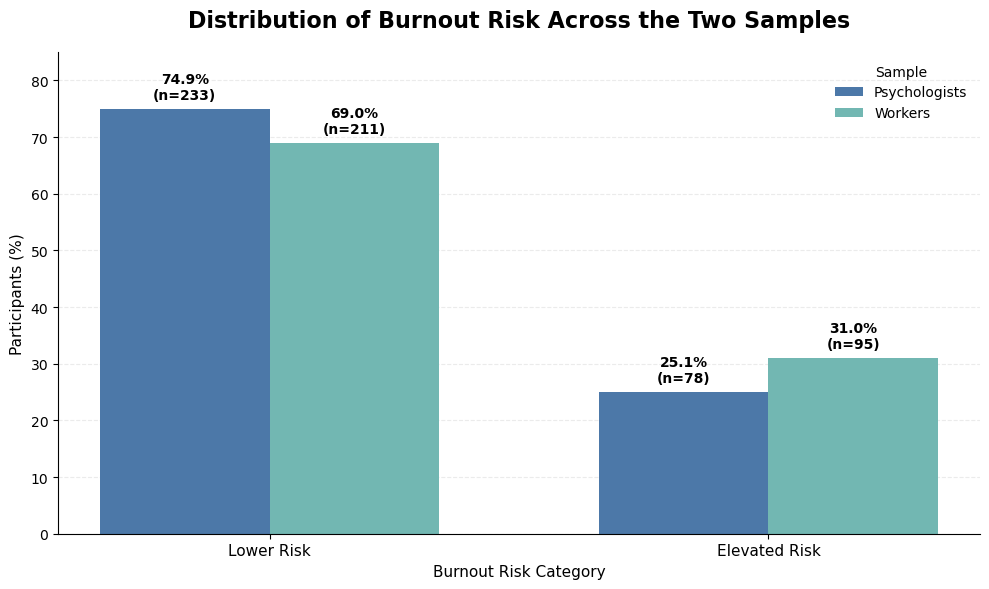

In [49]:

# BURNOUT RISK DISTRIBUTION 

import numpy as np
import matplotlib.pyplot as plt

# Percentage distributions
psych_percent = (
    y_psychologists.value_counts(normalize=True)
    .sort_index() * 100
)

worker_percent = (
    y_workers.value_counts(normalize=True)
    .sort_index() * 100
)

# Raw counts
psych_counts = y_psychologists.value_counts().sort_index()
worker_counts = y_workers.value_counts().sort_index()

risk_labels = ["Lower Risk", "Elevated Risk"]

x = np.arange(len(risk_labels))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width/2,
    psych_percent.values,
    width,
    label="Psychologists",
    color="#4C78A8"
)

bars2 = ax.bar(
    x + width/2,
    worker_percent.values,
    width,
    label="Workers",
    color="#72B7B2"
)

# Add percentage + participant count above each bar
for bars, counts in [
    (bars1, psych_counts.values),
    (bars2, worker_counts.values)
]:
    for bar, count in zip(bars, counts):
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 1.2,
            f"{height:.1f}%\n(n={count})",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

# Formatting
ax.set_title(
    "Distribution of Burnout Risk Across the Two Samples",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Burnout Risk Category",
    fontsize=11
)

ax.set_ylabel(
    "Participants (%)",
    fontsize=11
)

ax.set_xticks(x)
ax.set_xticklabels(risk_labels, fontsize=11)

ax.set_ylim(0, 85)

ax.legend(
    title="Sample",
    frameon=False,
    fontsize=10
)

# Cleaner appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Work Engagement and Burnout Risk

The UWES dimensions of Vigour, Dedication and Absorption were examined across the lower and elevated burnout-risk groups. This provides an initial descriptive assessment of whether work engagement differs according to burnout-risk classification before predictive modelling is performed.

In [50]:

# WORK ENGAGEMENT BY BURNOUT RISK
uwes_variables = [
    "UWES_Vigour",
    "UWES_Dedication",
    "UWES_Absorption"
]


psych_eda = psychologists.copy()
worker_eda = workers.copy()

psych_eda["Burnout_Risk_Label"] = psych_eda["Burnout_Risk"].map({
    0: "Lower Risk",
    1: "Elevated Risk"
})

worker_eda["Burnout_Risk_Label"] = worker_eda["Burnout_Risk"].map({
    0: "Lower Risk",
    1: "Elevated Risk"
})

# Calculate group means
psych_uwes_means = (
    psych_eda
    .groupby("Burnout_Risk_Label")[uwes_variables]
    .mean()
    .T
)

worker_uwes_means = (
    worker_eda
    .groupby("Burnout_Risk_Label")[uwes_variables]
    .mean()
    .T
)

print("PSYCHOLOGISTS - MEAN WORK ENGAGEMENT BY BURNOUT RISK")
print("=" * 65)
display(psych_uwes_means.round(3))

print("\nWORKERS - MEAN WORK ENGAGEMENT BY BURNOUT RISK")
print("=" * 65)
display(worker_uwes_means.round(3))

PSYCHOLOGISTS - MEAN WORK ENGAGEMENT BY BURNOUT RISK


Burnout_Risk_Label,Elevated Risk,Lower Risk
UWES_Vigour,3.145,4.484
UWES_Dedication,4.164,5.092
UWES_Absorption,3.502,4.343



WORKERS - MEAN WORK ENGAGEMENT BY BURNOUT RISK


Burnout_Risk_Label,Elevated Risk,Lower Risk
UWES_Vigour,3.054,4.415
UWES_Dedication,3.741,4.956
UWES_Absorption,3.411,4.331


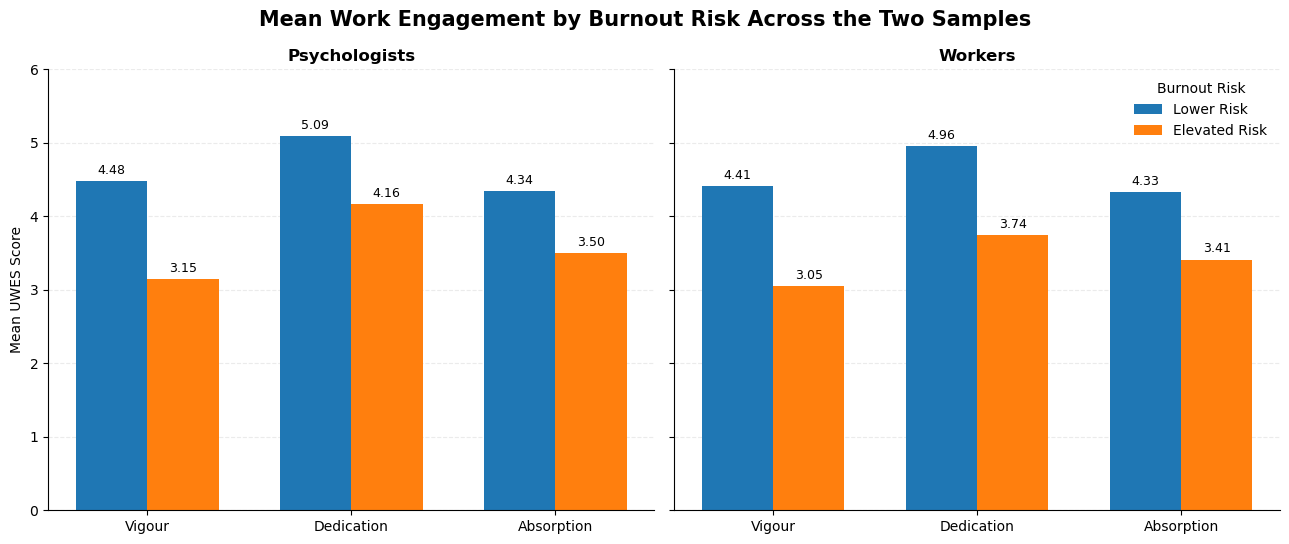

In [51]:

# WORK ENGAGEMENT BY BURNOUT RISK - EDA VISUALISATION
import numpy as np
import matplotlib.pyplot as plt

dimensions = ["Vigour", "Dedication", "Absorption"]
x = np.arange(len(dimensions))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

# Psychologists

psych_lower = [
    psych_uwes_means.loc["UWES_Vigour", "Lower Risk"],
    psych_uwes_means.loc["UWES_Dedication", "Lower Risk"],
    psych_uwes_means.loc["UWES_Absorption", "Lower Risk"]
]

psych_elevated = [
    psych_uwes_means.loc["UWES_Vigour", "Elevated Risk"],
    psych_uwes_means.loc["UWES_Dedication", "Elevated Risk"],
    psych_uwes_means.loc["UWES_Absorption", "Elevated Risk"]
]

bars1 = axes[0].bar(
    x - width/2,
    psych_lower,
    width,
    label="Lower Risk"
)

bars2 = axes[0].bar(
    x + width/2,
    psych_elevated,
    width,
    label="Elevated Risk"
)

axes[0].set_title("Psychologists", fontweight="bold")
axes[0].set_ylabel("Mean UWES Score")
axes[0].set_xticks(x)
axes[0].set_xticklabels(dimensions)
axes[0].set_ylim(0, 6)


# Workers

worker_lower = [
    worker_uwes_means.loc["UWES_Vigour", "Lower Risk"],
    worker_uwes_means.loc["UWES_Dedication", "Lower Risk"],
    worker_uwes_means.loc["UWES_Absorption", "Lower Risk"]
]

worker_elevated = [
    worker_uwes_means.loc["UWES_Vigour", "Elevated Risk"],
    worker_uwes_means.loc["UWES_Dedication", "Elevated Risk"],
    worker_uwes_means.loc["UWES_Absorption", "Elevated Risk"]
]

bars3 = axes[1].bar(
    x - width/2,
    worker_lower,
    width,
    label="Lower Risk"
)

bars4 = axes[1].bar(
    x + width/2,
    worker_elevated,
    width,
    label="Elevated Risk"
)

axes[1].set_title("Workers", fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(dimensions)
axes[1].set_ylim(0, 6)


# Value labels

for ax in axes:
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f",
            padding=3,
            fontsize=9
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

axes[1].legend(
    title="Burnout Risk",
    frameon=False
)

fig.suptitle(
    "Mean Work Engagement by Burnout Risk Across the Two Samples",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Emotional Distress and Burnout Risk

The DASS dimensions of Depression, Anxiety and Stress were examined across the lower and elevated burnout-risk groups. This descriptive comparison assesses whether emotional distress differs according to burnout-risk classification before predictive modelling.

In [52]:

# EMOTIONAL DISTRESS BY BURNOUT RISK=

dass_variables = [
    "DASS_Depression",
    "DASS_Anxiety",
    "DASS_Stress"
]

# Psychologists
psych_dass_means = (
    psych_eda
    .groupby("Burnout_Risk_Label")[dass_variables]
    .mean()
    .T
)

# Workers
worker_dass_means = (
    worker_eda
    .groupby("Burnout_Risk_Label")[dass_variables]
    .mean()
    .T
)

print("PSYCHOLOGISTS - MEAN EMOTIONAL DISTRESS BY BURNOUT RISK")
print("=" * 65)
display(psych_dass_means.round(3))

print("\nWORKERS - MEAN EMOTIONAL DISTRESS BY BURNOUT RISK")
print("=" * 65)
display(worker_dass_means.round(3))

PSYCHOLOGISTS - MEAN EMOTIONAL DISTRESS BY BURNOUT RISK


Burnout_Risk_Label,Elevated Risk,Lower Risk
DASS_Depression,1.333,0.519
DASS_Anxiety,0.921,0.360
DASS_Stress,1.484,0.807



WORKERS - MEAN EMOTIONAL DISTRESS BY BURNOUT RISK


Burnout_Risk_Label,Elevated Risk,Lower Risk
DASS_Depression,1.245,0.598
DASS_Anxiety,0.865,0.412
DASS_Stress,1.423,0.852


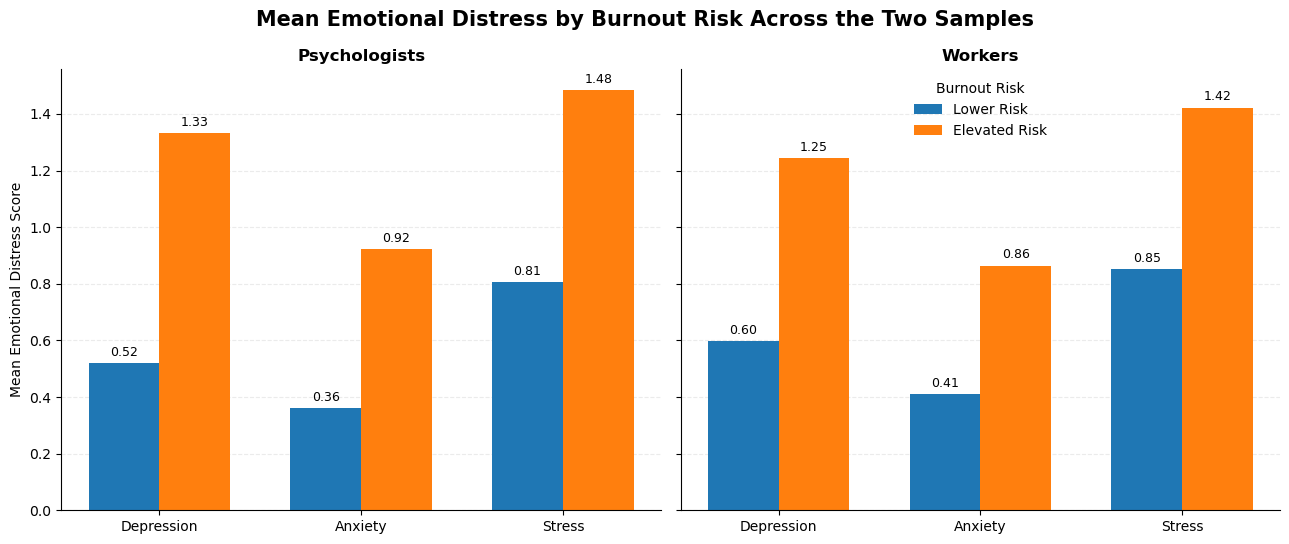

In [53]:

# EMOTIONAL DISTRESS BY BURNOUT RISK - EDA VISUALISATION

import numpy as np
import matplotlib.pyplot as plt

dimensions = ["Depression", "Anxiety", "Stress"]
x = np.arange(len(dimensions))
width = 0.35

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharey=True
)


# Psychologists


psych_lower = [
    psych_dass_means.loc["DASS_Depression", "Lower Risk"],
    psych_dass_means.loc["DASS_Anxiety", "Lower Risk"],
    psych_dass_means.loc["DASS_Stress", "Lower Risk"]
]

psych_elevated = [
    psych_dass_means.loc["DASS_Depression", "Elevated Risk"],
    psych_dass_means.loc["DASS_Anxiety", "Elevated Risk"],
    psych_dass_means.loc["DASS_Stress", "Elevated Risk"]
]

axes[0].bar(
    x - width/2,
    psych_lower,
    width,
    label="Lower Risk"
)

axes[0].bar(
    x + width/2,
    psych_elevated,
    width,
    label="Elevated Risk"
)

axes[0].set_title(
    "Psychologists",
    fontweight="bold"
)

axes[0].set_ylabel(
    "Mean Emotional Distress Score"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(dimensions)


# Workers


worker_lower = [
    worker_dass_means.loc["DASS_Depression", "Lower Risk"],
    worker_dass_means.loc["DASS_Anxiety", "Lower Risk"],
    worker_dass_means.loc["DASS_Stress", "Lower Risk"]
]

worker_elevated = [
    worker_dass_means.loc["DASS_Depression", "Elevated Risk"],
    worker_dass_means.loc["DASS_Anxiety", "Elevated Risk"],
    worker_dass_means.loc["DASS_Stress", "Elevated Risk"]
]

axes[1].bar(
    x - width/2,
    worker_lower,
    width,
    label="Lower Risk"
)

axes[1].bar(
    x + width/2,
    worker_elevated,
    width,
    label="Elevated Risk"
)

axes[1].set_title(
    "Workers",
    fontweight="bold"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(dimensions)

axes[1].legend(
    title="Burnout Risk",
    frameon=False
)



for ax in axes:

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f",
            padding=3,
            fontsize=9
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)


fig.suptitle(
    "Mean Emotional Distress by Burnout Risk Across the Two Samples",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Psychological Flexibility and Burnout Risk

Psychological flexibility-related constructs were examined across the lower and elevated burnout-risk groups using the AAQ-II psychological inflexibility score and the PPFI dimensions of Avoidance, Acceptance and Harnessing.

Because the AAQ-II and PPFI measures use different scoring ranges, their raw scores are examined separately rather than directly compared on a common numerical scale.

In [54]:

# PSYCHOLOGICAL FLEXIBILITY BY BURNOUT RISK

flexibility_variables = [
    "AAQ_Psychological_Inflexibility",
    "PPFI_Avoidance",
    "PPFI_Acceptance",
    "PPFI_Harnessing"
]

# Psychologists
psych_flex_means = (
    psych_eda
    .groupby("Burnout_Risk_Label")[flexibility_variables]
    .mean()
    .T
)

# Workers
worker_flex_means = (
    worker_eda
    .groupby("Burnout_Risk_Label")[flexibility_variables]
    .mean()
    .T
)

print("PSYCHOLOGISTS - MEAN PSYCHOLOGICAL FLEXIBILITY BY BURNOUT RISK")
print("=" * 70)
display(psych_flex_means.round(3))

print("\nWORKERS - MEAN PSYCHOLOGICAL FLEXIBILITY BY BURNOUT RISK")
print("=" * 70)
display(worker_flex_means.round(3))

PSYCHOLOGISTS - MEAN PSYCHOLOGICAL FLEXIBILITY BY BURNOUT RISK


Burnout_Risk_Label,Elevated Risk,Lower Risk
AAQ_Psychological_Inflexibility,29.897,21.382
PPFI_Avoidance,3.723,4.854
PPFI_Acceptance,4.751,5.155
PPFI_Harnessing,3.626,3.599



WORKERS - MEAN PSYCHOLOGICAL FLEXIBILITY BY BURNOUT RISK


Burnout_Risk_Label,Elevated Risk,Lower Risk
AAQ_Psychological_Inflexibility,30.211,22.270
PPFI_Avoidance,3.848,4.691
PPFI_Acceptance,4.629,5.037
PPFI_Harnessing,3.556,3.645


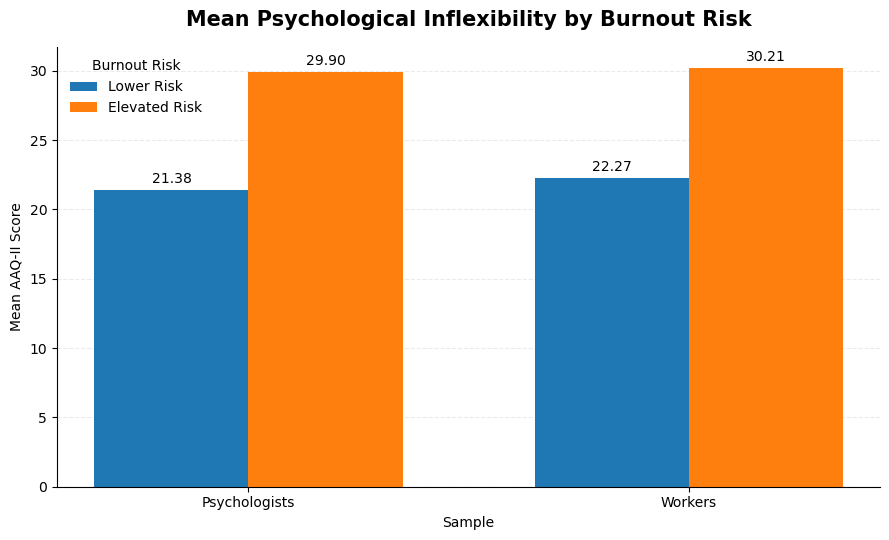

In [55]:

# PSYCHOLOGICAL INFLEXIBILITY BY BURNOUT RISK

samples = ["Psychologists", "Workers"]

lower_risk = [
    psych_flex_means.loc[
        "AAQ_Psychological_Inflexibility", "Lower Risk"
    ],
    worker_flex_means.loc[
        "AAQ_Psychological_Inflexibility", "Lower Risk"
    ]
]

elevated_risk = [
    psych_flex_means.loc[
        "AAQ_Psychological_Inflexibility", "Elevated Risk"
    ],
    worker_flex_means.loc[
        "AAQ_Psychological_Inflexibility", "Elevated Risk"
    ]
]

x = np.arange(len(samples))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))

bars1 = ax.bar(
    x - width/2,
    lower_risk,
    width,
    label="Lower Risk"
)

bars2 = ax.bar(
    x + width/2,
    elevated_risk,
    width,
    label="Elevated Risk"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=10
    )

ax.set_title(
    "Mean Psychological Inflexibility by Burnout Risk",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Mean AAQ-II Score")
ax.set_xlabel("Sample")

ax.set_xticks(x)
ax.set_xticklabels(samples)

ax.legend(
    title="Burnout Risk",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

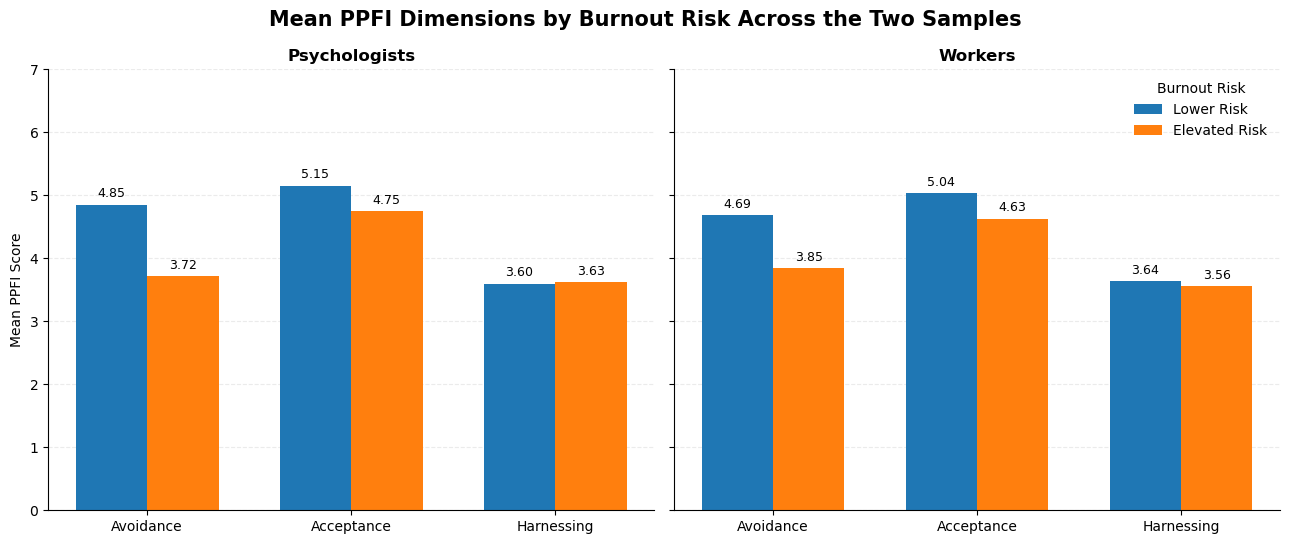

In [56]:

# PPFI DIMENSIONS BY BURNOUT RISK

dimensions = ["Avoidance", "Acceptance", "Harnessing"]
ppfi_variables = [
    "PPFI_Avoidance",
    "PPFI_Acceptance",
    "PPFI_Harnessing"
]

x = np.arange(len(dimensions))
width = 0.35

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharey=True
)

# Psychologists
psych_lower = [
    psych_flex_means.loc[v, "Lower Risk"]
    for v in ppfi_variables
]

psych_elevated = [
    psych_flex_means.loc[v, "Elevated Risk"]
    for v in ppfi_variables
]

axes[0].bar(
    x - width/2,
    psych_lower,
    width,
    label="Lower Risk"
)

axes[0].bar(
    x + width/2,
    psych_elevated,
    width,
    label="Elevated Risk"
)

axes[0].set_title("Psychologists", fontweight="bold")
axes[0].set_ylabel("Mean PPFI Score")
axes[0].set_xticks(x)
axes[0].set_xticklabels(dimensions)
axes[0].set_ylim(0, 7)


# Workers
worker_lower = [
    worker_flex_means.loc[v, "Lower Risk"]
    for v in ppfi_variables
]

worker_elevated = [
    worker_flex_means.loc[v, "Elevated Risk"]
    for v in ppfi_variables
]

axes[1].bar(
    x - width/2,
    worker_lower,
    width,
    label="Lower Risk"
)

axes[1].bar(
    x + width/2,
    worker_elevated,
    width,
    label="Elevated Risk"
)

axes[1].set_title("Workers", fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(dimensions)
axes[1].set_ylim(0, 7)

axes[1].legend(
    title="Burnout Risk",
    frameon=False
)

# Formatting
for ax in axes:
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f",
            padding=3,
            fontsize=9
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Mean PPFI Dimensions by Burnout Risk Across the Two Samples",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Psychosocial Work Environment and Burnout Risk

For the psychologist sample, COPSOQ-derived dimensions were examined across the lower and elevated burnout-risk groups. These dimensions represent psychosocial characteristics of the work environment, including job demands and workplace resources.

As COPSOQ variables were available only for the psychologist sample, this analysis was conducted independently and was not used for direct cross-sample comparison.

In [57]:

# PSYCHOSOCIAL WORK ENVIRONMENT BY BURNOUT RISK


copsoq_variables = [
    "COP_Quantitative_Demands",
    "COP_Cognitive_Demands",
    "COP_Emotional_Demands",
    "COP_Hiding_Emotions",
    "COP_Possibilities_Development",
    "COP_Social_Support",
    "COP_Social_Relations",
    "COP_Control"
]

psych_copsoq_means = (
    psych_eda
    .groupby("Burnout_Risk_Label")[copsoq_variables]
    .mean()
    .T
)

print("PSYCHOLOGISTS - MEAN PSYCHOSOCIAL WORK ENVIRONMENT")
print("BY BURNOUT RISK")
print("=" * 70)

display(psych_copsoq_means.round(3))

PSYCHOLOGISTS - MEAN PSYCHOSOCIAL WORK ENVIRONMENT
BY BURNOUT RISK


Burnout_Risk_Label,Elevated Risk,Lower Risk
COP_Quantitative_Demands,3.074,2.547
COP_Cognitive_Demands,4.292,4.062
COP_Emotional_Demands,4.410,4.140
COP_Hiding_Emotions,3.365,3.120
COP_Possibilities_Development,4.061,4.280
COP_Social_Support,2.798,3.082
COP_Social_Relations,3.333,3.309
COP_Control,2.814,3.474


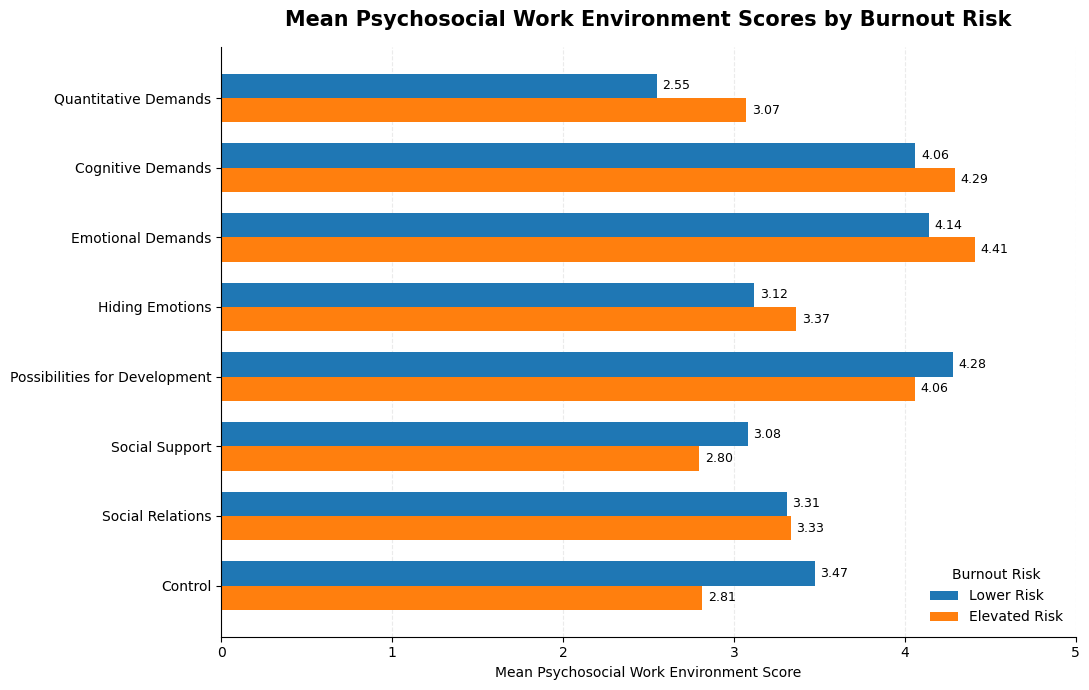

In [58]:

# PSYCHOSOCIAL WORK ENVIRONMENT BY BURNOUT RISK
# EDA VISUALISATION - PSYCHOLOGISTS


import numpy as np
import matplotlib.pyplot as plt

labels = [
    "Quantitative Demands",
    "Cognitive Demands",
    "Emotional Demands",
    "Hiding Emotions",
    "Possibilities for Development",
    "Social Support",
    "Social Relations",
    "Control"
]

variables = [
    "COP_Quantitative_Demands",
    "COP_Cognitive_Demands",
    "COP_Emotional_Demands",
    "COP_Hiding_Emotions",
    "COP_Possibilities_Development",
    "COP_Social_Support",
    "COP_Social_Relations",
    "COP_Control"
]

lower = [
    psych_copsoq_means.loc[v, "Lower Risk"]
    for v in variables
]

elevated = [
    psych_copsoq_means.loc[v, "Elevated Risk"]
    for v in variables
]

y = np.arange(len(labels))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 7))

bars1 = ax.barh(
    y - height/2,
    lower,
    height,
    label="Lower Risk"
)

bars2 = ax.barh(
    y + height/2,
    elevated,
    height,
    label="Elevated Risk"
)

# Value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=9
    )

ax.set_yticks(y)
ax.set_yticklabels(labels)

# Put first construct at the top
ax.invert_yaxis()

ax.set_xlim(0, 5)

ax.set_xlabel("Mean Psychosocial Work Environment Score")

ax.set_title(
    "Mean Psychosocial Work Environment Scores by Burnout Risk",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.legend(
    title="Burnout Risk",
    frameon=False,
    loc="lower right"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Model Development and Evaluation

Following exploratory analysis, the final modelling data were divided into training and held-out test sets using an 80/20 stratified split. Stratification was applied to preserve the distribution of lower and elevated burnout-risk classes within each subset.

The psychologist and worker samples were modelled independently using the same modelling framework. The held-out test sets were reserved for final model evaluation and were not used during model training or hyperparameter selection.

In [59]:

# STRATIFIED TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42


# PSYCHOLOGISTS

X_psych_train, X_psych_test, y_psych_train, y_psych_test = train_test_split(
    X_psychologists,
    y_psychologists,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_psychologists
)

# WORKERS


X_worker_train, X_worker_test, y_worker_train, y_worker_test = train_test_split(
    X_workers,
    y_workers,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_workers
)


# VALIDATE THE SPLITS


def display_split_summary(name, X_train, X_test, y_train, y_test):

    print(f"\n{name.upper()} - TRAIN/TEST SPLIT")
    print("=" * 60)

    print(f"Training observations: {len(X_train)}")
    print(f"Test observations:     {len(X_test)}")
    print(f"Number of predictors:  {X_train.shape[1]}")

    print("\nTraining target distribution:")
    train_summary = pd.DataFrame({
        "Count": y_train.value_counts().sort_index(),
        "Percentage": (
            y_train.value_counts(normalize=True)
            .sort_index() * 100
        ).round(1)
    })

    display(train_summary)

    print("Test target distribution:")
    test_summary = pd.DataFrame({
        "Count": y_test.value_counts().sort_index(),
        "Percentage": (
            y_test.value_counts(normalize=True)
            .sort_index() * 100
        ).round(1)
    })

    display(test_summary)


display_split_summary(
    "Psychologists",
    X_psych_train,
    X_psych_test,
    y_psych_train,
    y_psych_test
)

display_split_summary(
    "Workers",
    X_worker_train,
    X_worker_test,
    y_worker_train,
    y_worker_test
)


PSYCHOLOGISTS - TRAIN/TEST SPLIT
Training observations: 248
Test observations:     63
Number of predictors:  18

Training target distribution:


,Count,Percentage
Burnout_Risk,,
0,186,75.0
1,62,25.0


Test target distribution:


,Count,Percentage
Burnout_Risk,,
0,47,74.6
1,16,25.4



WORKERS - TRAIN/TEST SPLIT
Training observations: 244
Test observations:     62
Number of predictors:  10

Training target distribution:


,Count,Percentage
Burnout_Risk,,
0,168,68.9
1,76,31.1


Test target distribution:


,Count,Percentage
Burnout_Risk,,
0,43,69.4
1,19,30.6


### Model Preprocessing

Predictor standardisation was incorporated into the Logistic Regression pipeline because the harmonised predictor constructs were measured on different numerical scales. Standardisation parameters were estimated using the training data only to prevent information leakage from the held-out test set.

Decision Tree models were fitted using the original predictor scales because tree-based classification does not require feature standardisation.

In [60]:
# Model imports 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [61]:
# Baseline model configurations

# Logistic Regression
baseline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        random_state=RANDOM_STATE,
        max_iter=1000
    ))
])

# Decision Tree - Gini
baseline_dt_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=RANDOM_STATE
)

# Decision Tree - Entropy
baseline_dt_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=RANDOM_STATE
)

print("Baseline models configured successfully.")
print("\nModels:")
print("1. Logistic Regression")
print("2. Decision Tree - Gini")
print("3. Decision Tree - Entropy")

Baseline models configured successfully.

Models:
1. Logistic Regression
2. Decision Tree - Gini
3. Decision Tree - Entropy


### Baseline Model Evaluation

Baseline Logistic Regression and Decision Tree classifiers were evaluated using stratified 5-fold cross-validation on the training data. Stratification preserved the burnout-risk class distribution across folds.

Accuracy, precision, recall, F1-score and ROC-AUC were evaluated. Particular attention was given to recall and F1-score because the elevated-risk class represents the outcome of primary interest.

In [62]:

# BASELINE 5-FOLD STRATIFIED CROSS-VALIDATION

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}


def baseline_cross_validation(X_train, y_train, dataset_name):

    models = {
        "Logistic Regression": baseline_lr,
        "Decision Tree - Gini": baseline_dt_gini,
        "Decision Tree - Entropy": baseline_dt_entropy
    }

    results = []

    for model_name, model in models.items():

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        results.append({
            "Model": model_name,
            "Accuracy": scores["test_Accuracy"].mean(),
            "Precision": scores["test_Precision"].mean(),
            "Recall": scores["test_Recall"].mean(),
            "F1": scores["test_F1"].mean(),
            "ROC_AUC": scores["test_ROC_AUC"].mean()
        })

    results_df = pd.DataFrame(results)

    print(f"\n{dataset_name.upper()} - BASELINE 5-FOLD CROSS-VALIDATION")
    print("=" * 75)

    display(
        results_df
        .set_index("Model")
        .round(3)
    )

    return results_df

In [63]:

# RUN BASELINE CROSS-VALIDATION

psych_baseline_cv = baseline_cross_validation(
    X_psych_train,
    y_psych_train,
    "Psychologists"
)

worker_baseline_cv = baseline_cross_validation(
    X_worker_train,
    y_worker_train,
    "Workers"
)


PSYCHOLOGISTS - BASELINE 5-FOLD CROSS-VALIDATION


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.806,0.639,0.532,0.576,0.864
Decision Tree - Gini,0.754,0.503,0.514,0.507,0.674
Decision Tree - Entropy,0.746,0.484,0.417,0.443,0.636



WORKERS - BASELINE 5-FOLD CROSS-VALIDATION


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.799,0.704,0.617,0.656,0.871
Decision Tree - Gini,0.721,0.563,0.539,0.547,0.671
Decision Tree - Entropy,0.725,0.562,0.607,0.580,0.693


### Logistic Regression Statistical Inference

Separate inferential Logistic Regression models were fitted for the psychologist and worker samples to complement the predictive modelling analysis. The same researcher-validated predictor sets used in the primary predictive models were retained.

Coefficients, odds ratios, 95% confidence intervals and p-values were estimated to examine the adjusted statistical association between each predictor and elevated burnout risk. Statistical significance was assessed at p < 0.05.

These inferential results are interpreted as supplementary to the primary predictive analysis. Statistical significance is not treated as equivalent to predictive importance and does not imply causality.

In [64]:
import statsmodels.api as sm

# Prepare psychologist data for inferential Logistic Regression

psych_inference = psychologists[
    psychologist_final_predictors + ["Burnout_Risk"]
].dropna().copy()

X_psych_inference = psych_inference[
    psychologist_final_predictors
].astype(float)

y_psych_inference = psych_inference[
    "Burnout_Risk"
].astype(int)

# Add intercept
X_psych_inference_sm = sm.add_constant(
    X_psych_inference
)

print("Psychologist inferential sample size:",
      len(psych_inference))

print("\nNumber of predictors:",
      X_psych_inference.shape[1])

print("\nOutcome distribution:")
print(
    y_psych_inference.value_counts().sort_index()
)

Psychologist inferential sample size: 311

Number of predictors: 18

Outcome distribution:
Burnout_Risk
0    233
1     78
Name: count, dtype: int64


In [99]:
# Fit inferential Logistic Regression for psychologist sample

psych_inferential_lr = sm.Logit(
    y_psych_inference,
    X_psych_inference_sm
).fit(maxiter=100)

print(psych_inferential_lr.summary())

Optimization terminated successfully.
         Current function value: 0.304051
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:           Burnout_Risk   No. Observations:                  311
Model:                          Logit   Df Residuals:                      292
Method:                           MLE   Df Model:                           18
Date:                Wed, 07 Oct 2026   Pseudo R-squ.:                  0.4602
Time:                        12:50:07   Log-Likelihood:                -94.560
converged:                       True   LL-Null:                       -175.16
Covariance Type:            nonrobust   LLR p-value:                 4.848e-25
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              -0.7635      2.024     -0.377  

In [100]:
# Create inferential results table for psychologist sample

psych_ci = psych_inferential_lr.conf_int()

psych_inference_results = pd.DataFrame({
    "Predictor": psych_inferential_lr.params.index,
    "Coefficient": psych_inferential_lr.params.values,
    "Odds Ratio": np.exp(psych_inferential_lr.params.values),
    "CI Lower": np.exp(psych_ci[0].values),
    "CI Upper": np.exp(psych_ci[1].values),
    "p-value": psych_inferential_lr.pvalues.values
})

# Remove intercept
psych_inference_results = psych_inference_results[
    psych_inference_results["Predictor"] != "const"
].copy()

psych_inference_results["Significant (p < 0.05)"] = np.where(
    psych_inference_results["p-value"] < 0.05,
    "Yes",
    "No"
)

psych_inference_results["95% CI for OR"] = (
    psych_inference_results["CI Lower"].map("{:.3f}".format)
    + " – "
    + psych_inference_results["CI Upper"].map("{:.3f}".format)
)

psych_inference_table = psych_inference_results[
    [
        "Predictor",
        "Coefficient",
        "Odds Ratio",
        "95% CI for OR",
        "p-value",
        "Significant (p < 0.05)"
    ]
]

display(
    psych_inference_table.style
    .format({
        "Coefficient": "{:.3f}",
        "Odds Ratio": "{:.3f}",
        "p-value": lambda x: "<0.001" if x < 0.001 else f"{x:.3f}"
    })
    .background_gradient(
        subset=["Odds Ratio"],
        cmap="Blues"
    )
    .set_caption(
        "Inferential Logistic Regression Results – Psychologist Sample"
    )
    .hide(axis="index")
)

Predictor,Coefficient,Odds Ratio,95% CI for OR,p-value,Significant (p < 0.05)
COP_Quantitative_Demands,0.418,1.518,0.991 – 2.327,0.055,No
COP_Cognitive_Demands,0.510,1.665,0.849 – 3.265,0.138,No
COP_Emotional_Demands,0.022,1.022,0.580 – 1.799,0.940,No
COP_Hiding_Emotions,-0.452,0.637,0.429 – 0.945,0.025,Yes
COP_Possibilities_Development,-0.338,0.713,0.331 – 1.538,0.389,No
COP_Social_Support,0.001,1.001,0.677 – 1.480,0.998,No
COP_Social_Relations,0.203,1.225,0.708 – 2.121,0.468,No
COP_Control,-0.432,0.650,0.435 – 0.970,0.035,Yes
UWES_Vigour,-1.640,0.194,0.093 – 0.405,<0.001,Yes
UWES_Dedication,0.087,1.090,0.569 – 2.091,0.794,No


#### Psychologist Sample: Statistical Interpretation

The inferential Logistic Regression model was statistically significant overall (likelihood-ratio p < 0.001), indicating that the predictor set collectively showed evidence of association with elevated burnout risk.

Three predictors demonstrated statistically significant adjusted associations at p < 0.05. Hiding emotions (β = -0.452, p = 0.025), perceived control (β = -0.432, p = 0.035), and work-engagement vigour (β = -1.640, p < 0.001) showed negative associations with elevated burnout risk after adjustment for the remaining predictors. Vigour demonstrated the strongest significant association.

Quantitative demands (p = 0.055) and acceptance (p = 0.053) approached, but did not meet, the predefined 0.05 significance threshold. The remaining predictors were also not statistically significant after multivariable adjustment.

These findings represent adjusted statistical associations and should not be interpreted as causal effects. They complement the predictive model results rather than replacing measures of predictive performance and feature interpretation.

In [101]:
# Prepare worker data for inferential Logistic Regression

worker_inference = workers[
    worker_final_predictors + ["Burnout_Risk"]
].dropna().copy()

X_worker_inference = worker_inference[
    worker_final_predictors
].astype(float)

y_worker_inference = worker_inference[
    "Burnout_Risk"
].astype(int)

# Add intercept
X_worker_inference_sm = sm.add_constant(
    X_worker_inference
)

print("Worker inferential sample size:",
      len(worker_inference))

print("\nNumber of predictors:",
      X_worker_inference.shape[1])

print("\nOutcome distribution:")
print(
    y_worker_inference.value_counts().sort_index()
)

Worker inferential sample size: 306

Number of predictors: 10

Outcome distribution:
Burnout_Risk
0    211
1     95
Name: count, dtype: int64


In [102]:
# Fit inferential Logistic Regression for worker sample

worker_inferential_lr = sm.Logit(
    y_worker_inference,
    X_worker_inference_sm
).fit(maxiter=100)

print(worker_inferential_lr.summary())

Optimization terminated successfully.
         Current function value: 0.387009
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:           Burnout_Risk   No. Observations:                  306
Model:                          Logit   Df Residuals:                      295
Method:                           MLE   Df Model:                           10
Date:                Wed, 07 Oct 2026   Pseudo R-squ.:                  0.3753
Time:                        12:51:42   Log-Likelihood:                -118.42
converged:                       True   LL-Null:                       -189.56
Covariance Type:            nonrobust   LLR p-value:                 1.448e-25
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                               2.3530      1.260      1.867  

In [103]:
# Create inferential results table for worker sample

worker_ci = worker_inferential_lr.conf_int()

worker_inference_results = pd.DataFrame({
    "Predictor": worker_inferential_lr.params.index,
    "Coefficient": worker_inferential_lr.params.values,
    "Odds Ratio": np.exp(worker_inferential_lr.params.values),
    "CI Lower": np.exp(worker_ci[0].values),
    "CI Upper": np.exp(worker_ci[1].values),
    "p-value": worker_inferential_lr.pvalues.values
})

# Remove intercept
worker_inference_results = worker_inference_results[
    worker_inference_results["Predictor"] != "const"
].copy()

worker_inference_results["Significant (p < 0.05)"] = np.where(
    worker_inference_results["p-value"] < 0.05,
    "Yes",
    "No"
)

worker_inference_results["95% CI for OR"] = (
    worker_inference_results["CI Lower"].map("{:.3f}".format)
    + " – "
    + worker_inference_results["CI Upper"].map("{:.3f}".format)
)

worker_inference_table = worker_inference_results[
    [
        "Predictor",
        "Coefficient",
        "Odds Ratio",
        "95% CI for OR",
        "p-value",
        "Significant (p < 0.05)"
    ]
]

display(
    worker_inference_table.style
    .format({
        "Coefficient": "{:.3f}",
        "Odds Ratio": "{:.3f}",
        "p-value": lambda x: "<0.001" if x < 0.001 else f"{x:.3f}"
    })
    .background_gradient(
        subset=["Odds Ratio"],
        cmap="Blues"
    )
    .set_caption(
        "Inferential Logistic Regression Results – Worker Sample"
    )
    .hide(axis="index")
)

Predictor,Coefficient,Odds Ratio,95% CI for OR,p-value,Significant (p < 0.05)
UWES_Vigour,-1.529,0.217,0.114 – 0.412,<0.001,Yes
UWES_Dedication,-0.501,0.606,0.382 – 0.961,0.033,Yes
UWES_Absorption,0.586,1.796,1.025 – 3.148,0.041,Yes
AAQ_Psychological_Inflexibility,0.021,1.021,0.980 – 1.064,0.312,No
PPFI_Avoidance,-0.035,0.966,0.771 – 1.211,0.764,No
PPFI_Acceptance,0.133,1.142,0.807 – 1.617,0.453,No
PPFI_Harnessing,0.102,1.107,0.819 – 1.498,0.508,No
DASS_Depression,-0.255,0.775,0.409 – 1.470,0.435,No
DASS_Anxiety,0.451,1.570,0.779 – 3.163,0.207,No
DASS_Stress,0.918,2.505,1.240 – 5.061,0.010,Yes


#### Worker Sample: Statistical Interpretation

The inferential Logistic Regression model for the worker sample was statistically significant overall (likelihood-ratio p < 0.001), indicating that the predictor set collectively showed evidence of association with elevated burnout risk.

Four predictors demonstrated statistically significant adjusted associations at p < 0.05. Work-engagement vigour showed a negative association with elevated burnout risk (β = -1.529, p < 0.001), while dedication also showed a negative association (β = -0.501, p = 0.033). Absorption showed a positive adjusted association (β = 0.586, p = 0.041), while stress was positively associated with elevated burnout risk (β = 0.918, p = 0.010).

The remaining psychological-flexibility and emotional-symptom variables did not demonstrate statistically significant independent associations after adjustment for the other predictors. These findings represent multivariable statistical associations and should not be interpreted as causal effects or as substitutes for predictive model performance.

### Hyperparameter Tuning

Following baseline evaluation, hyperparameter tuning was conducted using stratified 5-fold cross-validation on the training data only. F1-score was used as the primary optimisation criterion because the study aims to identify elevated burnout risk while balancing the ability to detect elevated-risk cases with the reliability of positive classifications.

Logistic Regression and Decision Tree models were tuned independently for each sample. The held-out test sets remained excluded from hyperparameter selection.

In [65]:

# HYPERPARAMETER TUNING IMPORT

from sklearn.model_selection import GridSearchCV

In [66]:

# HYPERPARAMETER SEARCH SPACES

# Logistic Regression
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

# Decision Tree
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "class_weight": [None, "balanced"]
}

In [67]:

# HYPERPARAMETER TUNING FUNCTION


def tune_models(X_train, y_train, dataset_name):

    print(f"\n{dataset_name.upper()} - HYPERPARAMETER TUNING")
    print("=" * 70)

    
    # LOGISTIC REGRESSION


    lr_search = GridSearchCV(
        estimator=baseline_lr,
        param_grid=lr_param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    lr_search.fit(X_train, y_train)

    print("\nLOGISTIC REGRESSION")
    print("-" * 40)
    print(f"Best F1: {lr_search.best_score_:.3f}")
    print("Best parameters:")
    print(lr_search.best_params_)


  
    # DECISION TREE


    dt_search = GridSearchCV(
        estimator=DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),
        param_grid=dt_param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    dt_search.fit(X_train, y_train)

    print("\nDECISION TREE")
    print("-" * 40)
    print(f"Best F1: {dt_search.best_score_:.3f}")
    print("Best parameters:")
    print(dt_search.best_params_)

    return lr_search, dt_search

In [68]:

# TUNE MODELS FOR EACH SAMPLE

psych_lr_search, psych_dt_search = tune_models(
    X_psych_train,
    y_psych_train,
    "Psychologists"
)

worker_lr_search, worker_dt_search = tune_models(
    X_worker_train,
    y_worker_train,
    "Workers"
)


PSYCHOLOGISTS - HYPERPARAMETER TUNING

LOGISTIC REGRESSION
----------------------------------------
Best F1: 0.650
Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

DECISION TREE
----------------------------------------
Best F1: 0.644
Best parameters:
{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2}

WORKERS - HYPERPARAMETER TUNING

LOGISTIC REGRESSION
----------------------------------------
Best F1: 0.704
Best parameters:
{'classifier__C': 100, 'classifier__class_weight': 'balanced'}

DECISION TREE
----------------------------------------
Best F1: 0.704
Best parameters:
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2}


### Tuned Model Cross-Validation

Following hyperparameter optimisation, the selected Logistic Regression and Decision Tree configurations were evaluated across the training data using stratified 5-fold cross-validation. Multiple performance measures were examined to assess overall classification performance and the identification of elevated burnout-risk cases before final held-out evaluation.

In [69]:

# TUNED MODEL CROSS-VALIDATION

def evaluate_tuned_cv(
    X_train,
    y_train,
    lr_search,
    dt_search,
    dataset_name
):

    tuned_models = {
        "Tuned Logistic Regression": lr_search.best_estimator_,
        "Tuned Decision Tree": dt_search.best_estimator_
    }

    results = []

    for model_name, model in tuned_models.items():

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        results.append({
            "Model": model_name,
            "Accuracy": scores["test_Accuracy"].mean(),
            "Precision": scores["test_Precision"].mean(),
            "Recall": scores["test_Recall"].mean(),
            "F1": scores["test_F1"].mean(),
            "ROC_AUC": scores["test_ROC_AUC"].mean()
        })

    results_df = pd.DataFrame(results)

    print(
        f"\n{dataset_name.upper()} - "
        "TUNED 5-FOLD CROSS-VALIDATION"
    )
    print("=" * 75)

    display(
        results_df
        .set_index("Model")
        .round(3)
    )

    return results_df

In [70]:
psych_tuned_cv = evaluate_tuned_cv(
    X_psych_train,
    y_psych_train,
    psych_lr_search,
    psych_dt_search,
    "Psychologists"
)

worker_tuned_cv = evaluate_tuned_cv(
    X_worker_train,
    y_worker_train,
    worker_lr_search,
    worker_dt_search,
    "Workers"
)


PSYCHOLOGISTS - TUNED 5-FOLD CROSS-VALIDATION


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Tuned Logistic Regression,0.798,0.585,0.745,0.650,0.871
Tuned Decision Tree,0.782,0.563,0.773,0.644,0.835



WORKERS - TUNED 5-FOLD CROSS-VALIDATION


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Tuned Logistic Regression,0.795,0.646,0.788,0.704,0.874
Tuned Decision Tree,0.787,0.631,0.814,0.704,0.840


### Final Held-Out Test Evaluation

Following model development and hyperparameter optimisation, the selected Logistic Regression and Decision Tree configurations were fitted using the complete training data and evaluated once on the previously unseen held-out test sets.

Performance was assessed using accuracy, precision, recall, F1-score and ROC-AUC. Confusion matrices were additionally retained for subsequent analysis of lower-risk and elevated-risk classifications.

In [71]:

# FINAL HELD-OUT TEST EVALUATION

def evaluate_test_models(
    X_train,
    X_test,
    y_train,
    y_test,
    lr_search,
    dt_search,
    dataset_name
):

    models = {
        "Logistic Regression": lr_search.best_estimator_,
        "Decision Tree": dt_search.best_estimator_
    }

    results = []
    predictions = {}
    probabilities = {}
    confusion_matrices = {}

    for model_name, model in models.items():

        # Fit selected configuration on complete training set
        model.fit(X_train, y_train)

        # Predict held-out test observations
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        # Store outputs for later results analysis
        predictions[model_name] = y_pred
        probabilities[model_name] = y_prob
        confusion_matrices[model_name] = confusion_matrix(
            y_test,
            y_pred
        )

        # Calculate performance metrics
        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "F1": f1_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "ROC_AUC": roc_auc_score(y_test, y_prob)
        })

    results_df = pd.DataFrame(results)

    print(
        f"\n{dataset_name.upper()} - "
        "FINAL HELD-OUT TEST PERFORMANCE"
    )
    print("=" * 75)

    display(
        results_df
        .set_index("Model")
        .round(3)
    )

    return (
        results_df,
        predictions,
        probabilities,
        confusion_matrices
    )

In [72]:

# FINAL EVALUATION - PSYCHOLOGISTS

(
    psych_test_results,
    psych_predictions,
    psych_probabilities,
    psych_confusion_matrices
) = evaluate_test_models(
    X_psych_train,
    X_psych_test,
    y_psych_train,
    y_psych_test,
    psych_lr_search,
    psych_dt_search,
    "Psychologists"
)



# FINAL EVALUATION - WORKERS

(
    worker_test_results,
    worker_predictions,
    worker_probabilities,
    worker_confusion_matrices
) = evaluate_test_models(
    X_worker_train,
    X_worker_test,
    y_worker_train,
    y_worker_test,
    worker_lr_search,
    worker_dt_search,
    "Workers"
)


PSYCHOLOGISTS - FINAL HELD-OUT TEST PERFORMANCE


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.825,0.619,0.812,0.703,0.902
Decision Tree,0.698,0.448,0.812,0.578,0.771



WORKERS - FINAL HELD-OUT TEST PERFORMANCE


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.774,0.586,0.895,0.708,0.847
Decision Tree,0.726,0.533,0.842,0.653,0.853


Performance remained relatively consistent between cross-validation and held-out test evaluation, indicating that the selected models retained predictive performance on unseen observations within each sample.

### Confusion Matrix Analysis

Confusion matrices were examined for the final Logistic Regression and Decision Tree models to evaluate the types of classification errors produced on the held-out test sets. Particular attention was given to false-negative classifications, as these represent participants with elevated burnout risk who were incorrectly classified as lower risk.

In [73]:

# FINAL MODEL CONFUSION MATRICES

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion_matrices(
    confusion_matrices,
    dataset_name
):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(11, 4.5)
    )

    for ax, (model_name, cm) in zip(
        axes,
        confusion_matrices.items()
    ):

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Lower Risk", "Elevated Risk"]
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            colorbar=False,
            values_format="d"
        )

        ax.set_title(
            model_name,
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlabel("Predicted Burnout Risk")
        ax.set_ylabel("Actual Burnout Risk")

    fig.suptitle(
        f"Confusion Matrices for Final Models – {dataset_name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

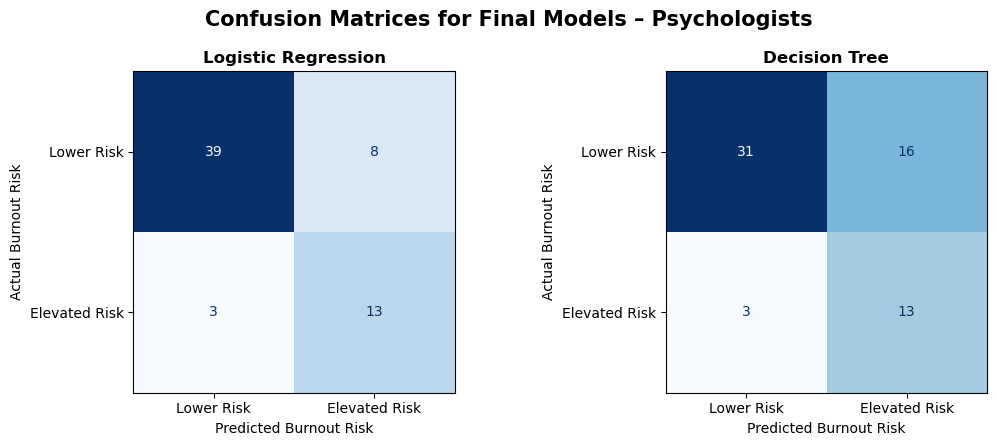

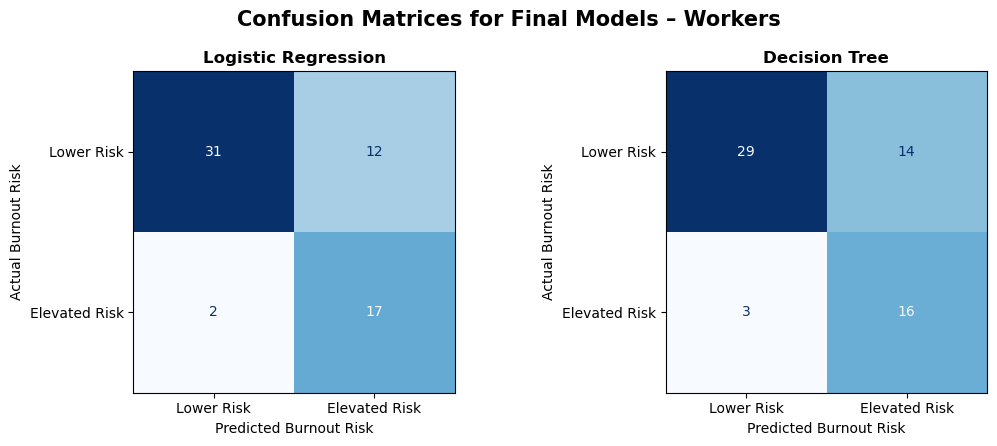

In [74]:
# Psychologists
plot_confusion_matrices(
    psych_confusion_matrices,
    "Psychologists"
)

# Workers
plot_confusion_matrices(
    worker_confusion_matrices,
    "Workers"
)

### ROC Curve Analysis

Receiver Operating Characteristic (ROC) curves were examined to assess the ability of the final models to discriminate between lower and elevated burnout-risk participants across classification thresholds. The Area Under the ROC Curve (ROC-AUC) was used to summarise overall discriminatory performance.

In [75]:

# ROC CURVES - FINAL HELD-OUT TEST RESULTS

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score


def plot_roc_curves(
    y_test,
    probabilities,
    dataset_name
):

    fig, ax = plt.subplots(figsize=(8, 6))

    for model_name, y_prob in probabilities.items():

        fpr, tpr, _ = roc_curve(
            y_test,
            y_prob
        )

        auc = roc_auc_score(
            y_test,
            y_prob
        )

        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model_name} (AUC = {auc:.3f})"
        )

    # Random-classification reference
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.5,
        label="Random Classifier (AUC = 0.500)"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")

    ax.set_title(
        f"ROC Curves for Final Models – {dataset_name}",
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    ax.legend(
        loc="lower right",
        frameon=False
    )

    ax.grid(
        linestyle="--",
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

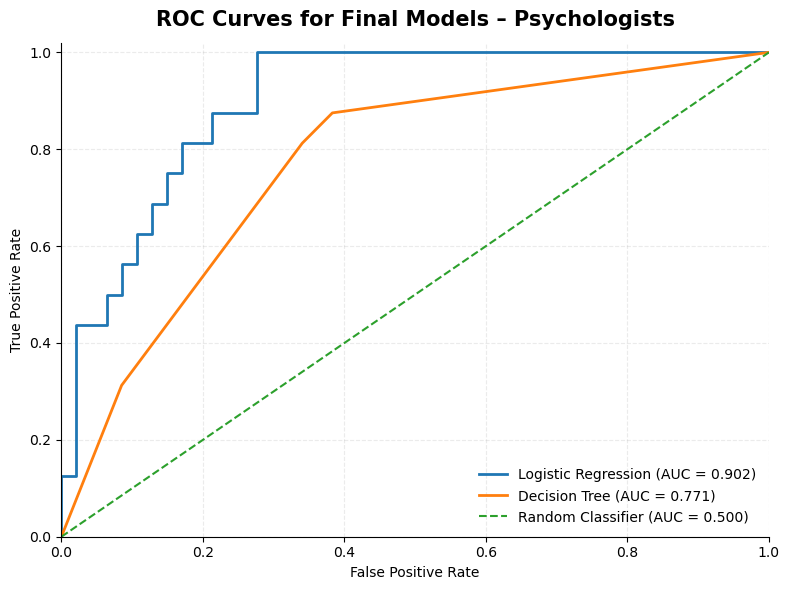

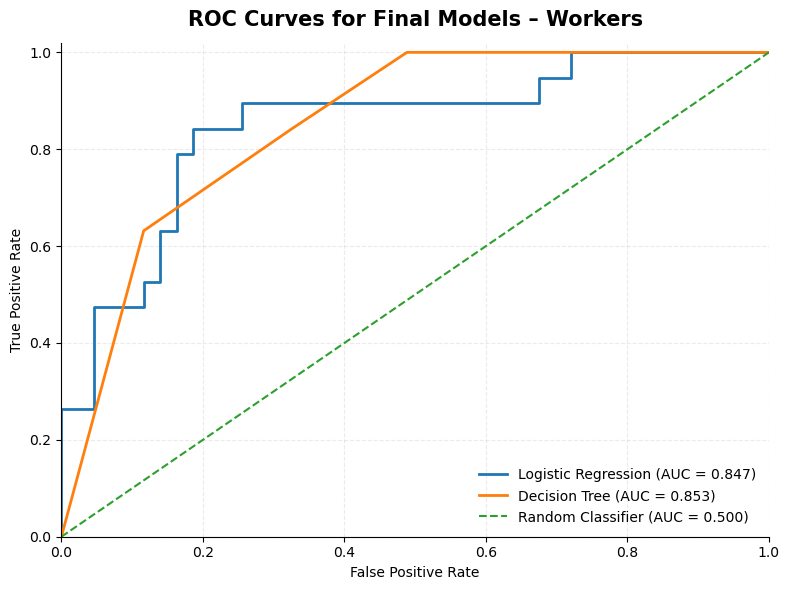

In [76]:
# Psychologists
plot_roc_curves(
    y_psych_test,
    psych_probabilities,
    "Psychologists"
)

# Workers
plot_roc_curves(
    y_worker_test,
    worker_probabilities,
    "Workers"
)

### Logistic Regression Predictor Interpretation

The coefficients of the final Logistic Regression models were examined to identify the direction and relative magnitude of predictor associations with elevated burnout-risk classification. As predictors were standardised within the modelling pipeline, coefficient magnitudes provide a comparable indication of predictor influence within each sample.

Positive coefficients indicate that higher predictor values were associated with a greater modelled likelihood of elevated burnout risk, while negative coefficients indicate an association with a lower modelled likelihood of elevated burnout risk.

In [77]:

# LOGISTIC REGRESSION COEFFICIENT INTERPRETATION

def extract_lr_coefficients(
    fitted_pipeline,
    feature_names,
    dataset_name
):

    lr_model = fitted_pipeline.named_steps["classifier"]

    coefficients = pd.DataFrame({
        "Predictor": feature_names,
        "Coefficient": lr_model.coef_[0]
    })

    coefficients["Absolute_Coefficient"] = (
        coefficients["Coefficient"].abs()
    )

    coefficients = coefficients.sort_values(
        "Absolute_Coefficient",
        ascending=False
    ).reset_index(drop=True)

    print(
        f"\n{dataset_name.upper()} - "
        "LOGISTIC REGRESSION COEFFICIENTS"
    )
    print("=" * 70)

    display(
        coefficients.round(3)
    )

    return coefficients

In [78]:

# EXTRACT FINAL LR COEFFICIENTS

psych_lr_coefficients = extract_lr_coefficients(
    psych_lr_search.best_estimator_,
    X_psych_train.columns,
    "Psychologists"
)

worker_lr_coefficients = extract_lr_coefficients(
    worker_lr_search.best_estimator_,
    X_worker_train.columns,
    "Workers"
)


PSYCHOLOGISTS - LOGISTIC REGRESSION COEFFICIENTS


,Predictor,Coefficient,Absolute_Coefficient
0,UWES_Vigour,-0.826,0.826
1,DASS_Anxiety,0.473,0.473
2,DASS_Stress,0.327,0.327
3,COP_Control,-0.304,0.304
4,DASS_Depression,0.273,0.273
5,COP_Hiding_Emotions,-0.248,0.248
6,COP_Cognitive_Demands,0.247,0.247
7,PPFI_Avoidance,-0.222,0.222
8,PPFI_Harnessing,0.204,0.204
9,COP_Quantitative_Demands,0.187,0.187



WORKERS - LOGISTIC REGRESSION COEFFICIENTS


,Predictor,Coefficient,Absolute_Coefficient
0,UWES_Vigour,-1.957,1.957
1,UWES_Absorption,0.717,0.717
2,DASS_Stress,0.654,0.654
3,UWES_Dedication,-0.523,0.523
4,PPFI_Acceptance,0.182,0.182
5,AAQ_Psychological_Inflexibility,0.153,0.153
6,PPFI_Avoidance,0.140,0.140
7,DASS_Anxiety,0.115,0.115
8,DASS_Depression,-0.059,0.059
9,PPFI_Harnessing,-0.056,0.056


#### Logistic Regression Coefficient Visualisation

Standardised Logistic Regression coefficients were visualised to examine the direction and relative magnitude of predictor associations within each final model. Coefficients above zero indicate a positive association with the modelled likelihood of elevated burnout risk, whereas coefficients below zero indicate a negative association. Coefficients should be interpreted conditionally within the multivariable model rather than as causal effects.

In [79]:

# LOGISTIC REGRESSION COEFFICIENT PLOTS

import matplotlib.pyplot as plt


def plot_lr_coefficients(
    coefficients,
    dataset_name
):

    # Sort from most negative to most positive
    plot_data = coefficients.sort_values(
        "Coefficient",
        ascending=True
    ).copy()

    fig, ax = plt.subplots(
        figsize=(10, max(6, len(plot_data) * 0.42))
    )

    bars = ax.barh(
        plot_data["Predictor"],
        plot_data["Coefficient"]
    )

    # Zero reference line
    ax.axvline(
        x=0,
        linewidth=1.2
    )

    # Add coefficient values
    for bar, value in zip(
        bars,
        plot_data["Coefficient"]
    ):

        if value >= 0:
            ax.text(
                value + 0.02,
                bar.get_y() + bar.get_height()/2,
                f"{value:.2f}",
                va="center",
                fontsize=9
            )
        else:
            ax.text(
                value - 0.02,
                bar.get_y() + bar.get_height()/2,
                f"{value:.2f}",
                va="center",
                ha="right",
                fontsize=9
            )

    ax.set_xlabel(
        "Standardised Logistic Regression Coefficient"
    )

    ax.set_ylabel("Predictor")

    ax.set_title(
        f"Logistic Regression Coefficients – {dataset_name}",
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

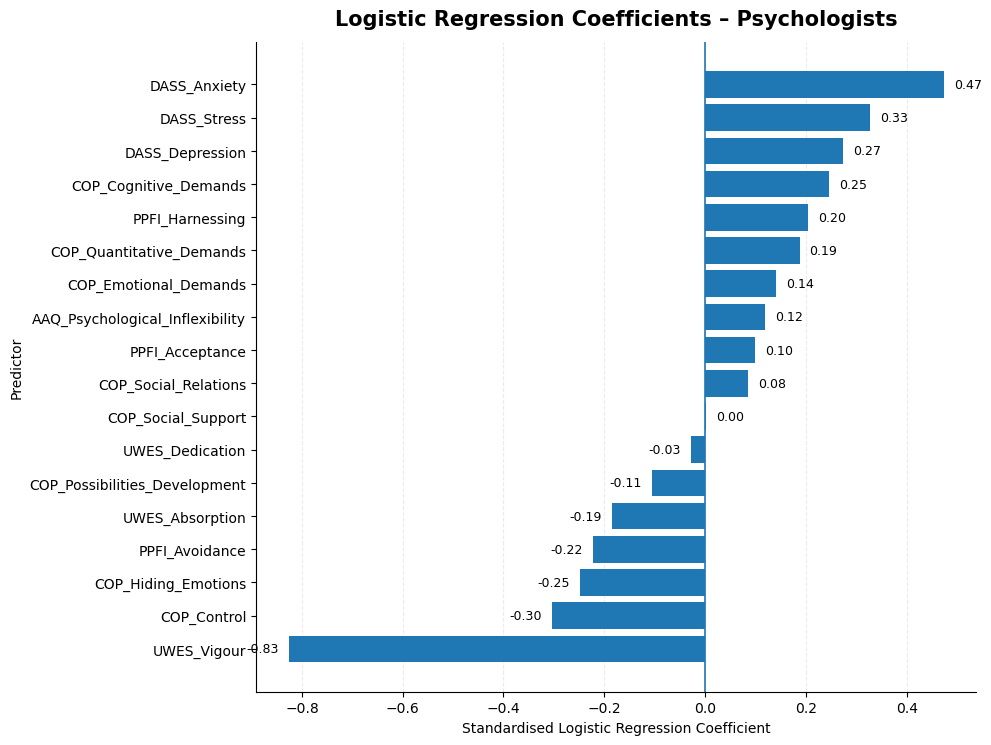

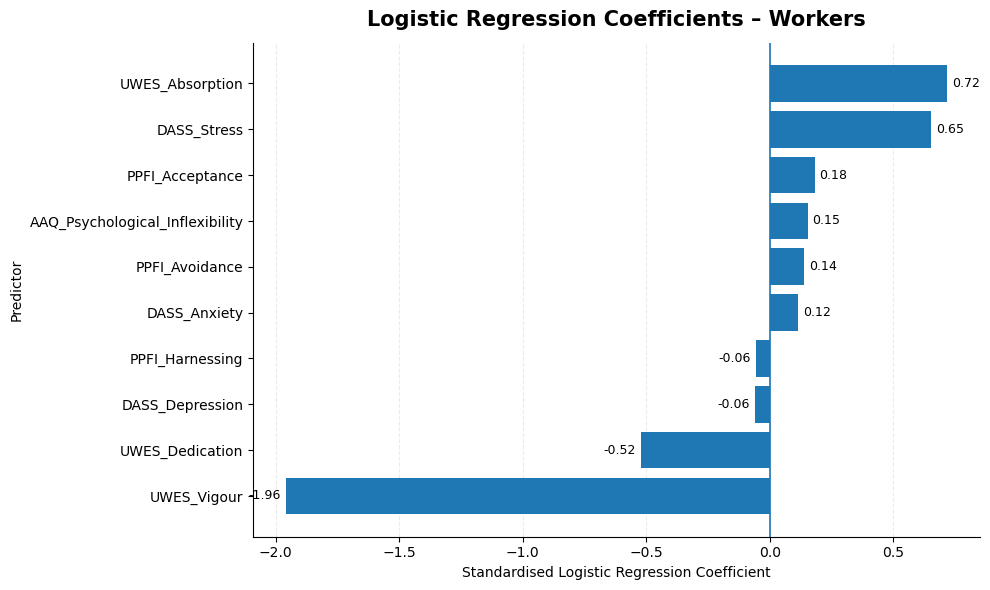

In [80]:
# Psychologists
plot_lr_coefficients(
    psych_lr_coefficients,
    "Psychologists"
)

# Workers
plot_lr_coefficients(
    worker_lr_coefficients,
    "Workers"
)

### Decision Tree Interpretation

The final Decision Tree models were examined to identify the hierarchical decision rules used to classify burnout risk. Hyperparameter optimisation selected a maximum tree depth of two for both samples, resulting in compact decision structures that can be directly inspected and interpreted.

In [81]:

# FINAL DECISION TREE VISUALISATION

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree


def plot_final_decision_tree(
    fitted_tree,
    feature_names,
    dataset_name
):

    fig, ax = plt.subplots(figsize=(16, 7))

    plot_tree(
        fitted_tree,
        feature_names=feature_names,
        class_names=["Lower Risk", "Elevated Risk"],
        filled=True,
        rounded=True,
        proportion=True,
        precision=2,
        fontsize=10,
        ax=ax
    )

    ax.set_title(
        f"Final Decision Tree – {dataset_name}",
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    plt.tight_layout()
    plt.show()

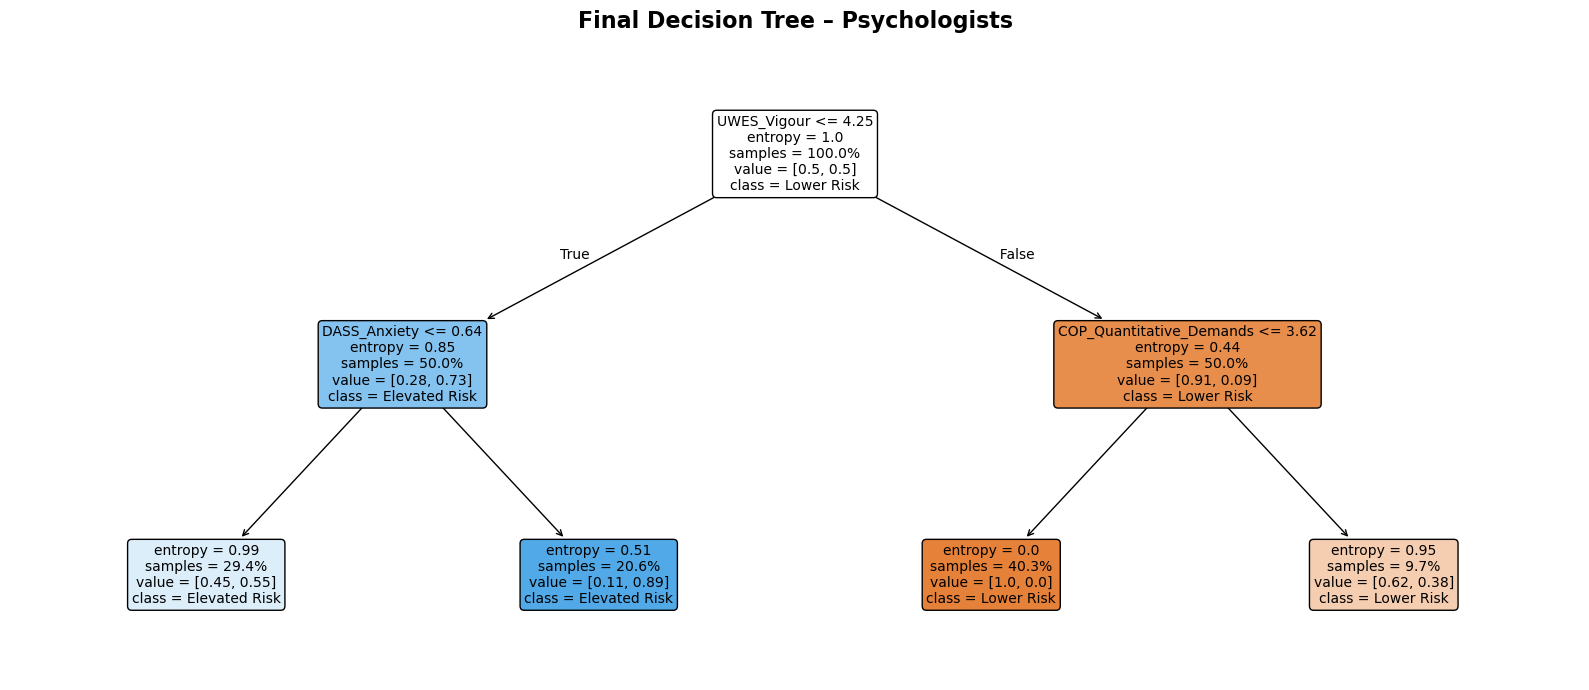

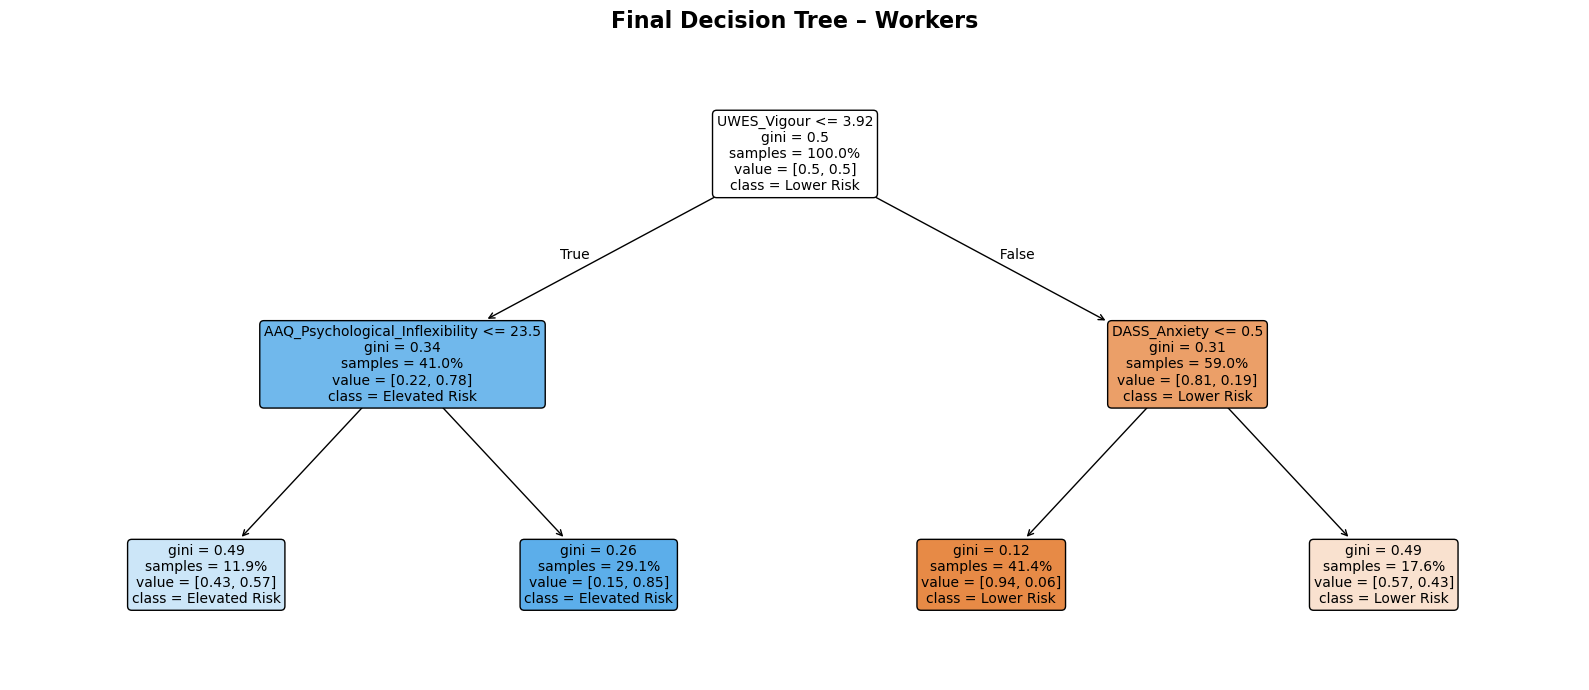

In [82]:

# PSYCHOLOGISTS DECISION TREE

plot_final_decision_tree(
    psych_dt_search.best_estimator_,
    X_psych_train.columns,
    "Psychologists"
)


# WORKERS DECISION TREE

plot_final_decision_tree(
    worker_dt_search.best_estimator_,
    X_worker_train.columns,
    "Workers"
)

Across both samples, UWES Vigor emerged prominently in both interpretable modelling approaches. It had the largest absolute Logistic Regression coefficient and formed the root split of both final Decision Trees, indicating that work-related vigour provided substantial discriminatory information for burnout-risk classification within these samples.

#### Decision Tree Predictor Importance

Decision Tree feature importance was examined to quantify the relative contribution of predictors used in the final tree structures. Importance values represent the normalised reduction in node impurity attributable to each predictor within the fitted tree. These values describe importance within the specific model and should not be interpreted as causal effects.

In [83]:

# DECISION TREE FEATURE IMPORTANCE

def extract_tree_importance(
    fitted_tree,
    feature_names,
    dataset_name
):

    importance_df = pd.DataFrame({
        "Predictor": feature_names,
        "Importance": fitted_tree.feature_importances_
    })

    # Keep only predictors actually used by the tree
    importance_df = (
        importance_df[
            importance_df["Importance"] > 0
        ]
        .sort_values(
            "Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        f"\n{dataset_name.upper()} - "
        "DECISION TREE FEATURE IMPORTANCE"
    )
    print("=" * 65)

    display(
        importance_df.round(3)
    )

    return importance_df

In [84]:
psych_dt_importance = extract_tree_importance(
    psych_dt_search.best_estimator_,
    X_psych_train.columns,
    "Psychologists"
)

worker_dt_importance = extract_tree_importance(
    worker_dt_search.best_estimator_,
    X_worker_train.columns,
    "Workers"
)


PSYCHOLOGISTS - DECISION TREE FEATURE IMPORTANCE


,Predictor,Importance
0,UWES_Vigour,0.673
1,COP_Quantitative_Demands,0.168
2,DASS_Anxiety,0.160



WORKERS - DECISION TREE FEATURE IMPORTANCE


,Predictor,Importance
0,UWES_Vigour,0.798
1,DASS_Anxiety,0.136
2,AAQ_Psychological_Inflexibility,0.066


#### Decision Tree Feature Importance Visualisation

Feature importance values from the final Decision Tree models were visualised to compare the relative contribution of predictors used in the classification structures across the two samples.

In [85]:

# DECISION TREE FEATURE IMPORTANCE VISUALISATION

import matplotlib.pyplot as plt


def plot_tree_importance(
    importance_df,
    dataset_name
):

    plot_data = importance_df.sort_values(
        "Importance",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))

    bars = ax.barh(
        plot_data["Predictor"],
        plot_data["Importance"]
    )

    # Add values
    for bar, value in zip(
        bars,
        plot_data["Importance"]
    ):
        ax.text(
            value + 0.01,
            bar.get_y() + bar.get_height()/2,
            f"{value:.3f}",
            va="center",
            fontsize=10
        )

    ax.set_xlabel("Feature Importance")
    ax.set_ylabel("Predictor")

    ax.set_title(
        f"Decision Tree Feature Importance – {dataset_name}",
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    ax.set_xlim(
        0,
        max(plot_data["Importance"]) * 1.18
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

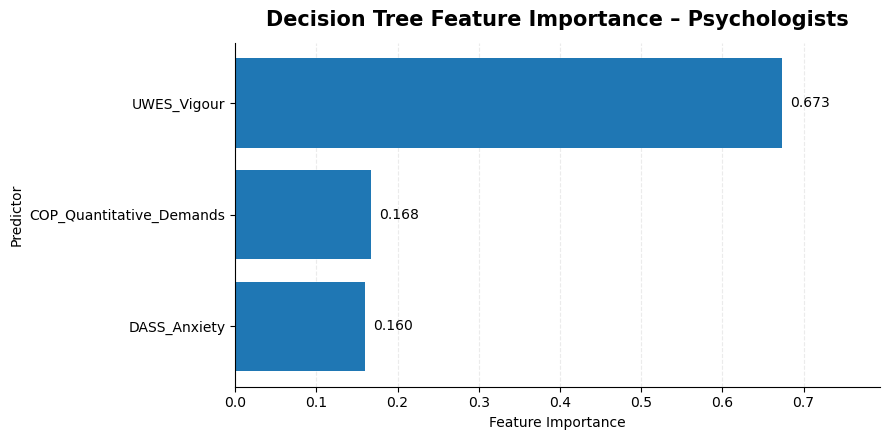

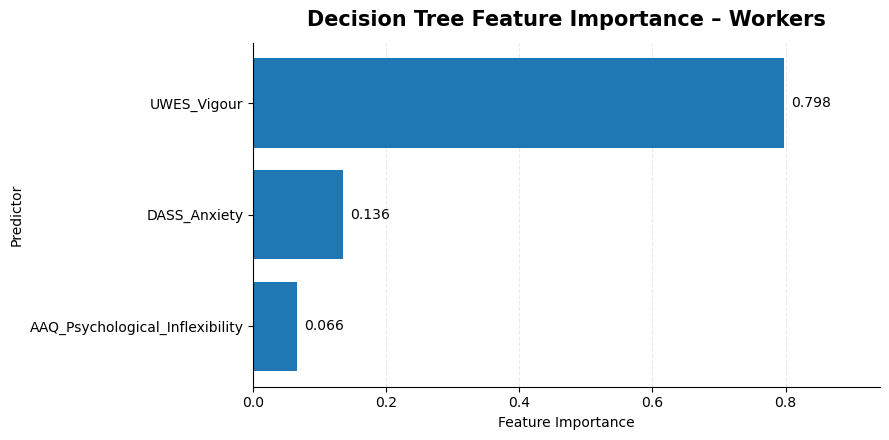

In [86]:
plot_tree_importance(
    psych_dt_importance,
    "Psychologists"
)

plot_tree_importance(
    worker_dt_importance,
    "Workers"
)

### Final Model Performance Comparison

Model performance was compared across baseline cross-validation, tuned cross-validation and final held-out test evaluation. This comparison was used to examine the effect of hyperparameter optimisation and assess whether model performance remained consistent when applied to previously unseen observations.

In [87]:

# CONSOLIDATED MODEL PERFORMANCE

def create_performance_summary(
    baseline_cv,
    tuned_cv,
    test_results,
    dataset_name
):

    baseline = baseline_cv.copy()

    # Keep the best baseline Decision Tree configuration
    baseline_lr = baseline[
        baseline["Model"] == "Logistic Regression"
    ].copy()

    baseline_dt = baseline[
        baseline["Model"].str.contains("Decision Tree")
    ].sort_values(
        "F1",
        ascending=False
    ).head(1).copy()

    baseline = pd.concat(
        [baseline_lr, baseline_dt],
        ignore_index=True
    )

    baseline["Model"] = baseline["Model"].replace(
        {
            "Decision Tree - Gini": "Decision Tree",
            "Decision Tree - Entropy": "Decision Tree"
        }
    )

    baseline["Evaluation_Stage"] = "Baseline CV"

    # Tuned CV
    tuned = tuned_cv.copy()

    tuned["Model"] = tuned["Model"].replace(
        {
            "Tuned Logistic Regression":
                "Logistic Regression",

            "Tuned Decision Tree":
                "Decision Tree"
        }
    )

    tuned["Evaluation_Stage"] = "Tuned CV"

    # Held-out test
    test = test_results.copy()
    test["Evaluation_Stage"] = "Held-Out Test"

    # Combine
    summary = pd.concat(
        [baseline, tuned, test],
        ignore_index=True
    )

    summary.insert(
        0,
        "Sample",
        dataset_name
    )

    summary = summary[
        [
            "Sample",
            "Evaluation_Stage",
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC"
        ]
    ]

    return summary

In [88]:
# Find variables containing likely model-result names
for name in globals():
    if any(word in name.lower() for word in ["baseline", "cv_result", "tuned"]):
        print(name)

baseline_lr
baseline_dt_gini
baseline_dt_entropy
baseline_cross_validation
psych_baseline_cv
worker_baseline_cv
evaluate_tuned_cv
psych_tuned_cv
worker_tuned_cv


In [89]:
#
# CONSOLIDATED MODEL PERFORMANCE

psych_performance_summary = create_performance_summary(
    psych_baseline_cv,
    psych_tuned_cv,
    psych_test_results,
    "Psychologists"
)

worker_performance_summary = create_performance_summary(
    worker_baseline_cv,
    worker_tuned_cv,
    worker_test_results,
    "Workers"
)

final_performance_summary = pd.concat(
    [
        psych_performance_summary,
        worker_performance_summary
    ],
    ignore_index=True
)

display(
    final_performance_summary.round(3)
)

,Sample,Evaluation_Stage,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Psychologists,Baseline CV,Logistic Regression,0.806,0.639,0.532,0.576,0.864
1,Psychologists,Baseline CV,Decision Tree,0.754,0.503,0.514,0.507,0.674
2,Psychologists,Tuned CV,Logistic Regression,0.798,0.585,0.745,0.650,0.871
3,Psychologists,Tuned CV,Decision Tree,0.782,0.563,0.773,0.644,0.835
4,Psychologists,Held-Out Test,Logistic Regression,0.825,0.619,0.812,0.703,0.902
5,Psychologists,Held-Out Test,Decision Tree,0.698,0.448,0.812,0.578,0.771
6,Workers,Baseline CV,Logistic Regression,0.799,0.704,0.617,0.656,0.871
7,Workers,Baseline CV,Decision Tree,0.725,0.562,0.607,0.580,0.693
8,Workers,Tuned CV,Logistic Regression,0.795,0.646,0.788,0.704,0.874
9,Workers,Tuned CV,Decision Tree,0.787,0.631,0.814,0.704,0.840


#### Model Performance Across Evaluation Stages

F1-score and recall were compared across baseline cross-validation, tuned cross-validation and held-out test evaluation. These measures were emphasised because the study focuses on the identification of elevated burnout-risk cases while accounting for the balance between positive predictive performance and sensitivity.

In [90]:
# MODEL PERFORMANCE ACROSS EVALUATION STAGES
import matplotlib.pyplot as plt


def plot_performance_progression(
    performance_df,
    dataset_name
):

    data = performance_df[
        performance_df["Sample"] == dataset_name
    ].copy()

    stage_order = [
        "Baseline CV",
        "Tuned CV",
        "Held-Out Test"
    ]

    models = [
        "Logistic Regression",
        "Decision Tree"
    ]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5),
        sharey=True
    )

    for ax, metric in zip(
        axes,
        ["Recall", "F1"]
    ):

        for model in models:

            model_data = data[
                data["Model"] == model
            ].set_index(
                "Evaluation_Stage"
            ).loc[stage_order]

            ax.plot(
                stage_order,
                model_data[metric],
                marker="o",
                linewidth=2,
                label=model
            )

            # Value labels
            for stage, value in zip(
                stage_order,
                model_data[metric]
            ):
                ax.text(
                    stage,
                    value + 0.018,
                    f"{value:.3f}",
                    ha="center",
                    fontsize=9
                )

        ax.set_title(
            metric,
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlabel("Evaluation Stage")
        ax.set_ylim(0.4, 1.0)

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.25
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0].set_ylabel("Performance Score")

    axes[1].legend(
        title="Model",
        frameon=False
    )

    fig.suptitle(
        f"Model Performance Across Evaluation Stages – {dataset_name}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

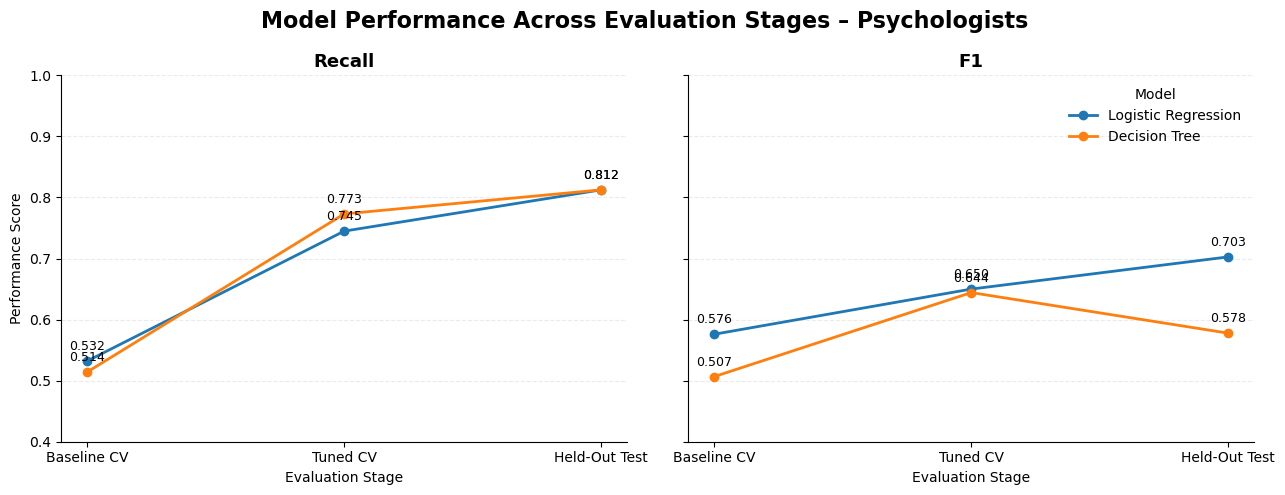

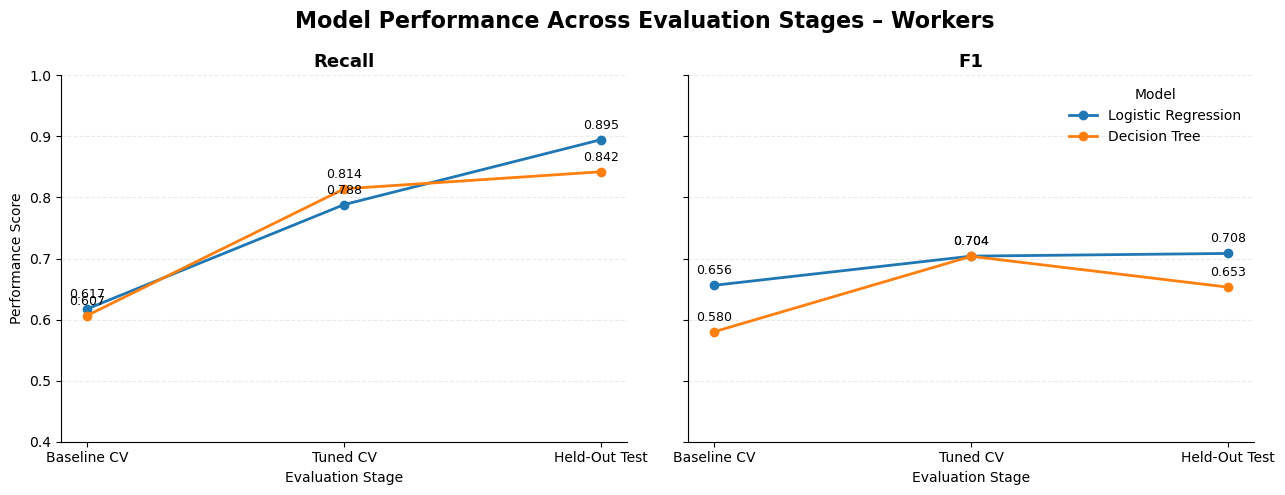

In [91]:
plot_performance_progression(
    final_performance_summary,
    "Psychologists"
)

plot_performance_progression(
    final_performance_summary,
    "Workers"
)

## Final Results Analysis

Following model evaluation and interpretation, the results were examined collectively to identify recurring patterns across the two samples and modelling approaches. Particular attention was given to predictors that demonstrated consistent relationships with burnout risk across exploratory analysis, Logistic Regression and Decision Tree modelling.

In [92]:

# CROSS-MODEL PREDICTOR CONSISTENCY

def create_predictor_consistency_summary(
    lr_coefficients,
    dt_importance,
    dataset_name,
    top_n=5
):

    # Top LR predictors by absolute coefficient
    lr_top = (
        lr_coefficients
        .nlargest(top_n, "Absolute_Coefficient")
        [["Predictor", "Coefficient"]]
        .copy()
    )

    lr_top["Sample"] = dataset_name
    lr_top["Model"] = "Logistic Regression"
    lr_top["Measure"] = "Coefficient"

    lr_top = lr_top.rename(
        columns={"Coefficient": "Value"}
    )

    # Decision Tree predictors actually used
    dt_top = dt_importance[
        ["Predictor", "Importance"]
    ].copy()

    dt_top["Sample"] = dataset_name
    dt_top["Model"] = "Decision Tree"
    dt_top["Measure"] = "Feature Importance"

    dt_top = dt_top.rename(
        columns={"Importance": "Value"}
    )

    return pd.concat(
        [lr_top, dt_top],
        ignore_index=True
    )

In [93]:
psych_predictor_summary = (
    create_predictor_consistency_summary(
        psych_lr_coefficients,
        psych_dt_importance,
        "Psychologists"
    )
)

worker_predictor_summary = (
    create_predictor_consistency_summary(
        worker_lr_coefficients,
        worker_dt_importance,
        "Workers"
    )
)

predictor_consistency_summary = pd.concat(
    [
        psych_predictor_summary,
        worker_predictor_summary
    ],
    ignore_index=True
)

display(
    predictor_consistency_summary.round(3)
)

,Predictor,Value,Sample,Model,Measure
0,UWES_Vigour,-0.826,Psychologists,Logistic Regression,Coefficient
1,DASS_Anxiety,0.473,Psychologists,Logistic Regression,Coefficient
2,DASS_Stress,0.327,Psychologists,Logistic Regression,Coefficient
3,COP_Control,-0.304,Psychologists,Logistic Regression,Coefficient
4,DASS_Depression,0.273,Psychologists,Logistic Regression,Coefficient
5,UWES_Vigour,0.673,Psychologists,Decision Tree,Feature Importance
6,COP_Quantitative_Demands,0.168,Psychologists,Decision Tree,Feature Importance
7,DASS_Anxiety,0.160,Psychologists,Decision Tree,Feature Importance
8,UWES_Vigour,-1.957,Workers,Logistic Regression,Coefficient
9,UWES_Absorption,0.717,Workers,Logistic Regression,Coefficient


### Effect Size Analysis by Burnout Risk

To complement the descriptive and predictive analyses, standardised mean differences were calculated between lower-risk and elevated-risk participants for the harmonised predictors. Cohen's d was used to quantify the magnitude and direction of group differences independently of sample size. Effect sizes were interpreted as descriptive measures of group separation rather than evidence of causality.

In [94]:

# COHEN'S D - BURNOUT RISK GROUP DIFFERENCES

import numpy as np
import pandas as pd


def calculate_cohens_d(
    df,
    predictors,
    target,
    dataset_name
):

    results = []

    for predictor in predictors:

        lower = df.loc[
            df[target] == 0,
            predictor
        ].dropna()

        elevated = df.loc[
            df[target] == 1,
            predictor
        ].dropna()

        # Pooled standard deviation
        pooled_sd = np.sqrt(
            (
                (len(lower) - 1) * lower.var(ddof=1)
                +
                (len(elevated) - 1) * elevated.var(ddof=1)
            )
            /
            (
                len(lower) + len(elevated) - 2
            )
        )

        d = (
            elevated.mean() - lower.mean()
        ) / pooled_sd

        results.append({
            "Predictor": predictor,
            "Lower_Risk_Mean": lower.mean(),
            "Elevated_Risk_Mean": elevated.mean(),
            "Cohens_d": d,
            "Absolute_d": abs(d)
        })

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        "Absolute_d",
        ascending=False
    ).reset_index(drop=True)

    print(
        f"\n{dataset_name.upper()} - "
        "BURNOUT RISK EFFECT SIZES"
    )
    print("=" * 70)

    display(
        results_df.round(3)
    )

    return results_df

In [95]:
for name in globals():
    if any(word in name.lower() for word in ["psych", "worker"]):
        if isinstance(globals()[name], pd.DataFrame):
            print(name, globals()[name].shape)

psychologists (311, 141)
workers (306, 107)
psychologist_corr (18, 18)
worker_corr (10, 10)
psychologist_vif (18, 2)
worker_vif (10, 2)
X_psychologists (311, 18)
X_workers (306, 10)
psych_eda (311, 141)
worker_eda (306, 107)
psych_uwes_means (3, 2)
worker_uwes_means (3, 2)
psych_dass_means (3, 2)
worker_dass_means (3, 2)
psych_flex_means (4, 2)
worker_flex_means (4, 2)
psych_copsoq_means (8, 2)
X_psych_train (248, 18)
X_psych_test (63, 18)
X_worker_train (244, 10)
X_worker_test (62, 10)
psych_baseline_cv (3, 6)
worker_baseline_cv (3, 6)
psych_inference (311, 19)
X_psych_inference (311, 18)
X_psych_inference_sm (311, 19)
psych_tuned_cv (2, 6)
worker_tuned_cv (2, 6)
psych_test_results (2, 6)
worker_test_results (2, 6)
psych_lr_coefficients (18, 3)
worker_lr_coefficients (10, 3)
psych_dt_importance (3, 2)
worker_dt_importance (3, 2)
psych_performance_summary (6, 8)
worker_performance_summary (6, 8)
psych_predictor_summary (8, 5)
worker_predictor_summary (8, 5)


In [96]:

# EFFECT SIZE ANALYSIS - FINAL MODEL PREDICTORS

psych_effect_sizes = calculate_cohens_d(
    psychologists,
    X_psychologists.columns.tolist(),
    "Burnout_Risk",
    "Psychologists"
)

worker_effect_sizes = calculate_cohens_d(
    workers,
    X_workers.columns.tolist(),
    "Burnout_Risk",
    "Workers"
)


PSYCHOLOGISTS - BURNOUT RISK EFFECT SIZES


,Predictor,Lower_Risk_Mean,Elevated_Risk_Mean,Cohens_d,Absolute_d
0,UWES_Vigour,4.484,3.145,-1.463,1.463
1,DASS_Depression,0.519,1.333,1.340,1.340
2,DASS_Stress,0.807,1.484,1.138,1.138
3,DASS_Anxiety,0.360,0.921,1.083,1.083
4,UWES_Dedication,5.092,4.164,-0.993,0.993
5,AAQ_Psychological_Inflexibility,21.382,29.897,0.935,0.935
6,UWES_Absorption,4.343,3.502,-0.849,0.849
7,PPFI_Avoidance,4.854,3.723,-0.750,0.750
8,COP_Control,3.474,2.814,-0.623,0.623
9,COP_Quantitative_Demands,2.547,3.074,0.543,0.543



WORKERS - BURNOUT RISK EFFECT SIZES


,Predictor,Lower_Risk_Mean,Elevated_Risk_Mean,Cohens_d,Absolute_d
0,UWES_Vigour,4.415,3.054,-1.468,1.468
1,UWES_Dedication,4.956,3.741,-1.164,1.164
2,DASS_Depression,0.598,1.245,0.986,0.986
3,DASS_Stress,0.852,1.423,0.957,0.957
4,UWES_Absorption,4.331,3.411,-0.889,0.889
5,AAQ_Psychological_Inflexibility,22.270,30.211,0.855,0.855
6,DASS_Anxiety,0.412,0.865,0.815,0.815
7,PPFI_Avoidance,4.691,3.848,-0.514,0.514
8,PPFI_Acceptance,5.037,4.629,-0.385,0.385
9,PPFI_Harnessing,3.645,3.556,-0.077,0.077


#### Burnout Risk Group Effect Sizes

Standardised mean differences were visualised for predictors demonstrating an absolute Cohen's d of at least 0.50. Positive values indicate higher mean scores among elevated-risk participants, whereas negative values indicate higher mean scores among lower-risk participants.

In [97]:
# EFFECT SIZE VISUALISATION

import matplotlib.pyplot as plt


def plot_effect_sizes(
    effect_sizes,
    dataset_name,
    threshold=0.50
):

    plot_data = effect_sizes[
        effect_sizes["Absolute_d"] >= threshold
    ].copy()

    plot_data = plot_data.sort_values(
        "Cohens_d",
        ascending=True
    )

    fig, ax = plt.subplots(
        figsize=(10, max(5, len(plot_data) * 0.55))
    )

    bars = ax.barh(
        plot_data["Predictor"],
        plot_data["Cohens_d"]
    )

    # Zero reference line
    ax.axvline(
        0,
        linewidth=1.2
    )

    # Value labels
    for bar, value in zip(
        bars,
        plot_data["Cohens_d"]
    ):

        offset = 0.03 if value >= 0 else -0.03

        ax.text(
            value + offset,
            bar.get_y() + bar.get_height()/2,
            f"{value:.2f}",
            va="center",
            ha="left" if value >= 0 else "right",
            fontsize=9
        )

    ax.set_xlabel("Cohen's d")
    ax.set_ylabel("Predictor")

    ax.set_title(
        f"Burnout Risk Group Effect Sizes – {dataset_name}",
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

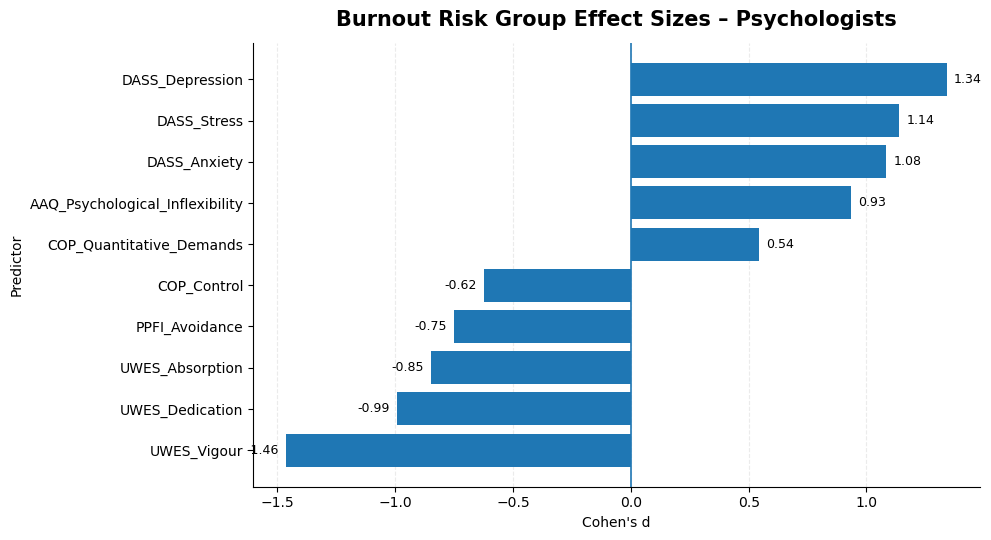

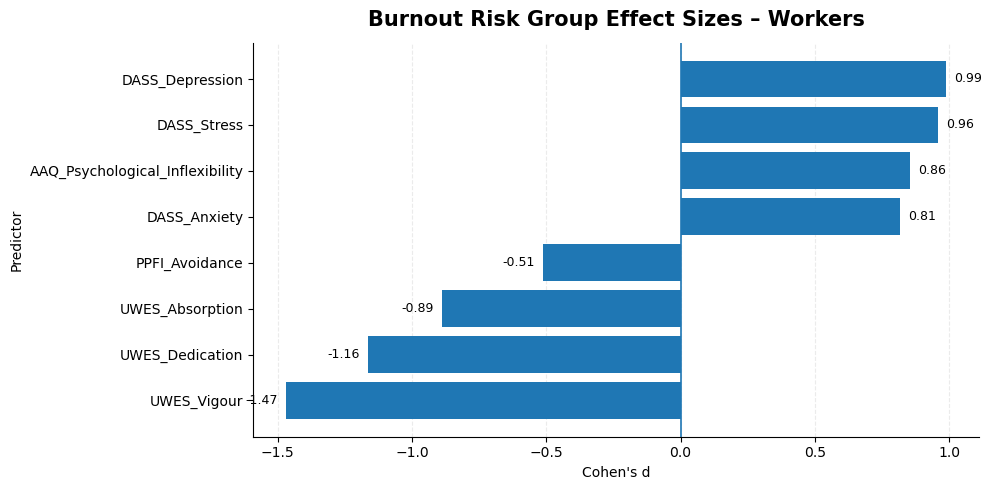

In [98]:
plot_effect_sizes(
    psych_effect_sizes,
    "Psychologists"
)

plot_effect_sizes(
    worker_effect_sizes,
    "Workers"
)

# Dataset 2 – Final Analysis Summary

## Dataset Overview

This analysis examined two independent samples from the dataset:

- **Psychologists:** n = 311
- **Workers:** n = 306

The two samples were analysed separately rather than merged. Instrument variables were validated and transformed into harmonised construct-level measures before modelling.

---

## Harmonised Predictor Framework

The analysis incorporated measures representing:

- **Work engagement:** UWES Vigor, Dedication and Absorption
- **Emotional distress:** DASS Depression, Anxiety and Stress
- **Psychological flexibility:** AAQ Psychological Inflexibility and PPFI dimensions
- **Psychosocial work environment:** COPSOQ dimensions, available for the psychologist sample

Following preprocessing and predictor validation:

- **Psychologists:** 18 final predictors
- **Workers:** 10 final predictors

No missing predictor values remained in the final modelling matrices.

---

## Burnout Risk Outcome

The harmonised binary target distinguished between:

- **Lower Risk (0)**
- **Elevated Risk (1)**

### Psychologists
- Lower Risk: 233 / 311 (**74.9%**)
- Elevated Risk: 78 / 311 (**25.1%**)

### Workers
- Lower Risk: 211 / 306 (**69.0%**)
- Elevated Risk: 95 / 306 (**31.0%**)

A stratified 80/20 train-test split was used to preserve the burnout-risk distribution in the training and held-out test samples.

---

## Exploratory Findings

Clear differences were observed between the Lower Risk and Elevated Risk groups.

Across both samples, elevated-risk participants generally demonstrated:

- Lower work engagement, particularly **Vigor and Dedication**
- Higher **Depression, Anxiety and Stress**
- Greater **Psychological Inflexibility**
- Lower scores on several psychological-resource measures

For psychologists, additional differences were observed across psychosocial workplace characteristics, including quantitative demands and perceived control.

---

## Effect Size Findings

Cohen's d was calculated to quantify standardised differences between the burnout-risk groups.

The largest effect in both samples was observed for **UWES Vigor**:

- Psychologists: **d = -1.463**
- Workers: **d = -1.468**

The negative direction indicates substantially lower Vigor among elevated-risk participants.

Other substantial effects occurred for:

### Psychologists
- Depression: **d = 1.340**
- Stress: **d = 1.138**
- Anxiety: **d = 1.083**
- Dedication: **d = -0.993**
- Psychological Inflexibility: **d = 0.935**
- Absorption: **d = -0.849**

### Workers
- Dedication: **d = -1.164**
- Depression: **d = 0.986**
- Stress: **d = 0.957**
- Absorption: **d = -0.889**
- Psychological Inflexibility: **d = 0.855**
- Anxiety: **d = 0.815**

These effect sizes were interpreted descriptively and do not imply causal relationships.

---

## Model Development

Two inherently interpretable machine-learning algorithms were evaluated:

1. **Logistic Regression**
2. **Decision Tree**

The modelling procedure consisted of:

1. Stratified 80/20 train-test splitting
2. Baseline 5-fold cross-validation
3. Hyperparameter optimisation
4. Tuned 5-fold cross-validation
5. Final evaluation using the untouched held-out test set

Hyperparameter optimisation prioritised **F1-score**, while class weighting was used to improve identification of the minority Elevated Risk class.

---

## Selected Hyperparameters

### Psychologists

**Logistic Regression**
- C = 0.1
- class_weight = balanced

**Decision Tree**
- criterion = entropy
- max_depth = 2
- min_samples_leaf = 1
- min_samples_split = 2
- class_weight = balanced

### Workers

**Logistic Regression**
- C = 100
- class_weight = balanced

**Decision Tree**
- criterion = gini
- max_depth = 2
- min_samples_leaf = 1
- min_samples_split = 2
- class_weight = balanced

---

## Final Held-Out Test Performance

### Psychologists

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.825 | 0.619 | 0.812 | 0.703 | 0.902 |
| Decision Tree | 0.698 | 0.448 | 0.812 | 0.578 | 0.771 |

### Workers

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.774 | 0.586 | 0.895 | 0.708 | 0.847 |
| Decision Tree | 0.726 | 0.533 | 0.842 | 0.653 | 0.853 |

Logistic Regression provided the strongest overall balance of predictive performance across the two samples, particularly when considering recall and F1-score.

---

## Confusion Matrix Findings

### Psychologists

**Logistic Regression**
- True Lower Risk: 39
- False Elevated Risk: 8
- Missed Elevated Risk: 3
- Correctly identified Elevated Risk: 13

**Decision Tree**
- True Lower Risk: 31
- False Elevated Risk: 16
- Missed Elevated Risk: 3
- Correctly identified Elevated Risk: 13

### Workers

**Logistic Regression**
- True Lower Risk: 31
- False Elevated Risk: 12
- Missed Elevated Risk: 2
- Correctly identified Elevated Risk: 17

**Decision Tree**
- True Lower Risk: 29
- False Elevated Risk: 14
- Missed Elevated Risk: 3
- Correctly identified Elevated Risk: 16

The final Logistic Regression models detected most Elevated Risk observations in both held-out samples.

---

## Model Interpretation

### Logistic Regression

**UWES Vigor** had the largest absolute standardised Logistic Regression coefficient in both samples:

- Psychologists: **-0.826**
- Workers: **-1.957**

The negative coefficients indicate that higher Vigor was associated with a lower predicted probability of Elevated Risk, holding the other model predictors constant.

Emotional distress measures also contributed to prediction, particularly Anxiety and Stress.

### Decision Tree

UWES Vigor was the **root splitting variable in both final Decision Trees**.

Feature importance:

**Psychologists**
- UWES Vigor: **0.673**
- Quantitative Demands: **0.168**
- Anxiety: **0.160**

**Workers**
- UWES Vigor: **0.798**
- Anxiety: **0.136**
- Psychological Inflexibility: **0.066**

This indicates that Vigor provided the greatest reduction in node impurity within both fitted Decision Trees.

---

## Overall Interpretation

The two independently analysed samples produced a consistent overall pattern.

Lower work engagement, particularly **lower Vigor**, was strongly associated with elevated burnout-risk classification. Elevated-risk participants also tended to demonstrate greater emotional distress and psychological inflexibility.

UWES Vigor emerged as the most consistent predictor across:

- Descriptive group comparisons
- Effect-size analysis
- Logistic Regression
- Decision Tree splitting
- Decision Tree feature importance
- Both independent samples

At the same time, differences in the remaining predictors between psychologists and workers indicate that burnout-risk prediction may involve both **shared and sample-specific indicators**.

The findings therefore support the feasibility of using interpretable machine-learning models to identify elevated occupational burnout risk while retaining transparency regarding the variables contributing to predictions.

These findings represent predictive associations and group differences and should not be interpreted as evidence of causal relationships.